# Poultry Disease Classification from Fecal Images
### ResNet50 transfer-learning baseline on the Zenodo poultry disease dataset

**Type:** image-based classification prototype for research and decision support. This is not a veterinary diagnostic tool.

**Classes (fixed order):** `Coccidiosis`, `Healthy`, `Salmonella`, `NCD` (Newcastle Disease)

---

## 1. Project Overview

**Goal.** Build a clean, reproducible baseline that classifies a poultry fecal photograph into one of four classes, so it can later be wrapped into an end-to-end application.

**Data.** The public Zenodo poultry disease dataset, stored in Google Drive:

| Source | Folders used | Role |
|---|---|---|
| `version-2` | `cocci/`, `healthy/`, `salmo/`, `ncd/` | Field images with folder-level labels |
| `version-3` | `pcrcocci/`, `pcrhealthy/`, `pcrsalmo/`, `pcrncd/` | PCR-confirmed samples, tracked as a separate source (`version-3-pcr`) |

`version-2/imgSegmentation/` and `version-2/imgObjDet_Yolo/` belong to other tasks (segmentation, detection) and are **explicitly excluded**. The discovery code only walks the eight class folders listed above, and an assertion later verifies that no excluded path entered the dataset.

**Method.** ResNet50 (ImageNet weights) + GlobalAveragePooling + Dropout + Dense(4, softmax), trained in two phases (frozen backbone, then partial fine-tuning of the last stage).

**What this notebook deliberately does not do:** object detection, segmentation, YOLO, transformers, ensembles or multimodal inputs. The point is a trustworthy baseline.

**Workflow**
1. Audit every image (readability, format, size, channels, hashes) and record anything rejected.
2. Remove exact duplicates and group suspicious/near duplicates **before** splitting, so no duplicate can straddle train/validation/test.
3. Split deterministically (seed 42), stratified by class, at the level of duplicate groups.
4. Train, select the checkpoint on validation macro-F1, then evaluate on the held-out test set exactly once.
5. Evaluate separately on the PCR-confirmed images, with honest labelling of whether that evaluation is external.
6. Error analysis, Grad-CAM, export, inference functions, and a packaged output directory.

**Scientific honesty.** No number in the markdown of this notebook is a result. All reported metrics are computed by the code cells at run time.

## 2. Environment Setup

Imports, library versions and GPU information. Everything used here ships with Google Colab (TensorFlow, Keras, NumPy, pandas, scikit-learn, matplotlib, seaborn, Pillow, OpenCV), so there is nothing to `pip install`.

**Why:** recording exact versions is part of reproducibility. A model trained on one TensorFlow/Keras version may serialize differently from another.

In [1]:
# ---- Standard library ----
import os, sys, re, json, time, random, shutil, hashlib, platform, subprocess, warnings
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor

# ---- Scientific stack ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import PIL
from PIL import Image
import cv2

# ---- Deep learning ----
import tensorflow as tf
from tensorflow import keras

# ---- Metrics / splitting ----
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, log_loss,
    precision_recall_fscore_support, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
)

from IPython.display import display

try:
    from tqdm.auto import tqdm
except ImportError:  # tqdm is preinstalled on Colab; this is only a fallback
    def tqdm(iterable, **kwargs):
        return iterable

warnings.filterwarnings("ignore", category=UserWarning, module="PIL")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Let TensorFlow allocate GPU memory on demand instead of grabbing all of it.
GPUS = tf.config.list_physical_devices("GPU")
for _gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(_gpu, True)
    except RuntimeError as e:
        print("Could not set memory growth:", e)

def _gpu_names():
    names = []
    for g in GPUS:
        try:
            names.append(tf.config.experimental.get_device_details(g).get("device_name", g.name))
        except Exception:
            names.append(g.name)
    return names

ENV_INFO = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "opencv": cv2.__version__,
    "pillow": PIL.__version__,
    "platform": platform.platform(),
    "in_colab": IN_COLAB,
    "gpus": _gpu_names(),
}
for k, v in ENV_INFO.items():
    print(f"{k:>14}: {v}")

if shutil.which("nvidia-smi"):
    print("\n" + subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
if not GPUS:
    print("\nWARNING: no GPU detected. In Colab use Runtime > Change runtime type > GPU. "
          "The notebook still runs on CPU, just much more slowly.")

        python: 3.13.16
    tensorflow: 2.21.0
         keras: 3.13.2
         numpy: 2.1.3
        pandas: 2.2.3
  scikit_learn: 1.6.1
        opencv: 5.0.0
        pillow: 11.3.0
      platform: Linux-6.6.159+-x86_64-with-glibc2.39
      in_colab: True
          gpus: ['Tesla T4']

Thu Oct 29 19:09:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       O

## 3. Configuration

Every tunable value lives here. Nothing below this cell hardcodes a path or hyperparameter.

**Experiment mode** (`USE_PCR_AS_EXTERNAL_TEST`):

| Setting | Train / validation | Main test | PCR evaluation |
|---|---|---|---|
| `True` (default, recommended) | Version 2 only | Held-out Version 2 images | **All** Version 3 PCR images. Never seen in training, so this is a genuine external (cross-source) evaluation. |
| `False` (combined) | Version 2 + Version 3, stratified by class and source | Held-out images from both versions | Only the Version 3 images that landed in the held-out test split. These come from the **same pool** as the training data, so this is a sub-group analysis, **not** an external evaluation. |

The external mode answers the more useful question: *does a model trained on field-labelled images agree with PCR-confirmed labels on images from a different collection?* The combined mode uses more training data but cannot answer that question.

**Where outputs go.** Every run writes directly to your Google Drive, in `MyDrive/poultry-output/<run id>/` (models, results, figures, Grad-CAM, config), with the best training checkpoint in `MyDrive/poultry-output/checkpoints/<run id>/` and an optional `<run id>.zip`. Nothing you need is kept only in `/content`, so a Colab disconnect cannot delete results. Only the local copy of the dataset lives in `/content`, and that is just a cache. Each run gets its own folder, so earlier runs are never overwritten.

In [2]:
# =============================== PATHS =======================================
DATASET_ROOT = "/content/drive/MyDrive/poultry-disease-dataset-zenedo"   # <- the only path you should need to change
OUTPUT_ROOT = "/content/drive/MyDrive/poultry-output"   # ALL outputs are written here, in your Drive (survive disconnects)
RUN_NAME = None                     # None = "run_<UTC timestamp>"; or set a name, e.g. "run_external_seed42"
MAKE_ZIP = True                     # also write <run>.zip next to the run folder (one file, easy to download)
COPY_TO_LOCAL = True                # copy class folders from Drive to local disk for fast training I/O
LOCAL_DATA_ROOT = "/content/poultry-data-local"   # local data CACHE only; losing it on disconnect is harmless
COPY_WORKERS = 32                   # parallel Drive -> local copy threads (Drive latency, not CPU, is the bottleneck)

# ============================ EXPERIMENT =====================================
USE_PCR_AS_EXTERNAL_TEST = True     # True: train on V2, evaluate externally on all V3 PCR images
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_HEAD = 15                    # phase 1: frozen backbone
EPOCHS_FINE = 20                    # phase 2: partial fine-tuning (set 0 to skip)
LEARNING_RATE = 1e-3                # phase 1 learning rate (Adam)
LEARNING_RATE_FINE = 1e-5           # phase 2 learning rate (AdamW)
WEIGHT_DECAY_FINE = 1e-4
DROPOUT_RATE = 0.3
NUM_CLASSES = 4
FINE_TUNE_STAGES = ("conv5_",)      # ResNet50 layer-name prefixes to unfreeze in phase 2; add "conv4_" to go deeper
EARLY_STOPPING_PATIENCE = 5
REDUCE_LR_PATIENCE = 2
REDUCE_LR_FACTOR = 0.3
MIN_LR = 1e-7
RESNET_WEIGHTS = "imagenet"

TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
IMBALANCE_THRESHOLD = 1.5           # use class weights if max/min class count in train exceeds this
USE_NEAR_DUPLICATE_GROUPING = True  # group visually identical images (perceptual dHash) so they share a split
MIN_IMAGE_SIDE = 32                 # images smaller than this (px) are rejected
TF_DECODE_CHECK = True              # verify every image decodes with TensorFlow before training
CACHE_IN_MEMORY = True              # cache resized uint8 images in RAM (roughly 150 KB per image at 224x224)
DETERMINISTIC_OPS = False           # True = bitwise-deterministic TF ops (slower; some GPU kernels unsupported)
AUDIT_WORKERS = 8
EXPORT_SAVEDMODEL = True            # extra TF SavedModel for serving/TFLite (adds ~2x the .keras size to the zip)

# Augmentation strengths (training only). Deliberately modest, see Section 11.
AUGMENTATION = {
    "flip": "horizontal_and_vertical",
    "rotation_factor": 0.08,        # fraction of a full turn, about +/-29 degrees
    "zoom_factor": 0.10,
    "contrast_factor": 0.15,
    "brightness_factor": 0.10,
}

# ========================= CLASSES AND SOURCES ===============================
CLASS_NAMES = ["Coccidiosis", "Healthy", "Salmonella", "NCD"]    # fixed order = fixed class ids
CLASS_DISPLAY_NAMES = {"Coccidiosis": "Coccidiosis", "Healthy": "Healthy",
                       "Salmonella": "Salmonella", "NCD": "Newcastle Disease (NCD)"}
CLASS_TO_INDEX = {c: i for i, c in enumerate(CLASS_NAMES)}
assert len(CLASS_NAMES) == NUM_CLASSES

V2_SOURCE, PCR_SOURCE = "version-2", "version-3-pcr"

# version directory -> (source label, {folder name -> class name})
SOURCE_FOLDERS = {
    "version-2": (V2_SOURCE, {"cocci": "Coccidiosis", "healthy": "Healthy",
                              "salmo": "Salmonella", "ncd": "NCD"}),
    "version-3": (PCR_SOURCE, {"pcrcocci": "Coccidiosis", "pcrhealthy": "Healthy",
                               "pcrsalmo": "Salmonella", "pcrncd": "NCD"}),
}
EXCLUDED_FOLDERS = {"imgsegmentation", "imgobjdet_yolo"}   # compared case-insensitively
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# Architecture names (used by Grad-CAM and the exported config)
BACKBONE_NAME = "resnet50_backbone"
LAST_CONV_LAYER = "conv5_block3_out"
HEAD_LAYER_NAMES = ("global_average_pooling", "dropout", "classifier")

# =============================== DERIVED =====================================
# Mount Drive here, before any output folder is created: creating folders under /content/drive
# before mounting would block the mount.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
elif OUTPUT_ROOT.startswith("/content/drive"):
    OUTPUT_ROOT = os.path.abspath("poultry-output")      # running outside Colab: keep outputs next to the notebook

RUN_ID = RUN_NAME or "run_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR = os.path.join(OUTPUT_ROOT, RUN_ID)                       # e.g. MyDrive/poultry-output/run_20261030_101500
CHECKPOINT_DIR = os.path.join(OUTPUT_ROOT, "checkpoints", RUN_ID)    # best weights during training, outside the zip
if os.path.exists(OUTPUT_DIR) and os.listdir(OUTPUT_DIR):
    raise FileExistsError(f"{OUTPUT_DIR} already has files. Choose another RUN_NAME (or leave it None).")
MODELS_DIR = os.path.join(OUTPUT_DIR, "models")
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
GRADCAM_DIR = os.path.join(OUTPUT_DIR, "gradcam")
CONFIG_DIR = os.path.join(OUTPUT_DIR, "config")
for d in (OUTPUT_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR, GRADCAM_DIR, CONFIG_DIR, CHECKPOINT_DIR):
    os.makedirs(d, exist_ok=True)
BEST_WEIGHTS_PATH = os.path.join(CHECKPOINT_DIR, "best.weights.h5")
MODEL_PATH = os.path.join(MODELS_DIR, "poultry_resnet50.keras")
SAVEDMODEL_PATH = os.path.join(MODELS_DIR, "poultry_resnet50_savedmodel")

# ============================ REPRODUCIBILITY ================================
def set_global_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

set_global_seed(SEED)
if DETERMINISTIC_OPS:
    tf.config.experimental.enable_op_determinism()

# ============================ SMALL HELPERS ==================================
def to_jsonable(obj):
    """Recursively convert numpy / pandas types so json.dump never fails."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, float) and np.isnan(obj):
        return None
    if isinstance(obj, np.ndarray):
        return to_jsonable(obj.tolist())
    return obj

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(to_jsonable(obj), f, indent=2)

def save_figure(fig, name):
    path = os.path.join(FIGURES_DIR, name)
    fig.savefig(path)
    return path

EXPERIMENT_CONFIG = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "experiment_mode": "v2_train__v3_pcr_external_test" if USE_PCR_AS_EXTERNAL_TEST else "combined_v2_v3",
    "use_pcr_as_external_test": USE_PCR_AS_EXTERNAL_TEST,
    "dataset_root": DATASET_ROOT,
    "run_id": RUN_ID, "output_dir": OUTPUT_DIR,
    "source_folders": {k: {"source_version": v[0], "folders": v[1]} for k, v in SOURCE_FOLDERS.items()},
    "excluded_folders": sorted(EXCLUDED_FOLDERS),
    "seed": SEED, "img_size": list(IMG_SIZE), "batch_size": BATCH_SIZE,
    "epochs_head": EPOCHS_HEAD, "epochs_fine": EPOCHS_FINE,
    "learning_rate": LEARNING_RATE, "learning_rate_fine": LEARNING_RATE_FINE,
    "weight_decay_fine": WEIGHT_DECAY_FINE, "dropout_rate": DROPOUT_RATE,
    "fine_tune_stages": list(FINE_TUNE_STAGES), "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "reduce_lr_patience": REDUCE_LR_PATIENCE, "reduce_lr_factor": REDUCE_LR_FACTOR, "min_lr": MIN_LR,
    "split_fractions": {"train": TRAIN_FRAC, "val": VAL_FRAC, "test": TEST_FRAC},
    "imbalance_threshold": IMBALANCE_THRESHOLD, "near_duplicate_grouping": USE_NEAR_DUPLICATE_GROUPING,
    "min_image_side": MIN_IMAGE_SIDE, "augmentation": AUGMENTATION,
    "class_names": CLASS_NAMES, "class_to_index": CLASS_TO_INDEX,
    "deterministic_ops": DETERMINISTIC_OPS, "environment": ENV_INFO,
}
save_json(EXPERIMENT_CONFIG, os.path.join(CONFIG_DIR, "experiment_config.json"))
print("Mode:", EXPERIMENT_CONFIG["experiment_mode"])
print("Outputs ->", OUTPUT_DIR)

Mounted at /content/drive
Mode: v2_train__v3_pcr_external_test
Outputs -> /content/drive/MyDrive/poultry-output/run_20261029_191001


## 4. Google Drive Mount

Drive is mounted in the Configuration cell (it must be mounted before the output folders are created). This cell confirms the mount and that the dataset root exists before doing anything expensive.

In [3]:
if IN_COLAB and not os.path.ismount("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
elif not IN_COLAB:
    print("Not running in Colab: no Drive mount. DATASET_ROOT must point to a local copy.")

if not os.path.isdir(DATASET_ROOT):
    raise FileNotFoundError(
        f"DATASET_ROOT not found: {DATASET_ROOT}\n"
        "Check the folder name in Drive (note the dataset folder is spelled 'zenedo') and update DATASET_ROOT.")
print("Top level of DATASET_ROOT:", sorted(os.listdir(DATASET_ROOT)))
print("This run's outputs  ->", OUTPUT_DIR)

Top level of DATASET_ROOT: ['training-output', 'version-2', 'version-3']
This run's outputs  -> /content/drive/MyDrive/poultry-output/run_20261029_191001


## 5. Dataset Structure

Inspect every sub-folder of `version-2/` and `version-3/` and classify it as **INCLUDED** (mapped to a class), **EXCLUDED** (a known non-classification task folder) or **IGNORED** (not part of the mapping). Folder-name matching is case-insensitive so small naming differences in Drive do not silently drop a class.

In [4]:
def find_child_dir(parent, name):
    """Case-insensitive lookup of a direct sub-directory. Returns the real path or None."""
    if not os.path.isdir(parent):
        return None
    exact = os.path.join(parent, name)
    if os.path.isdir(exact):
        return exact
    for entry in os.listdir(parent):
        if entry.lower() == name.lower() and os.path.isdir(os.path.join(parent, entry)):
            return os.path.join(parent, entry)
    return None

def count_files(folder):
    return sum(len(files) for _, _, files in os.walk(folder))

structure_rows, CLASS_FOLDERS, missing = [], [], []
for version_dir, (source_label, folder_map) in SOURCE_FOLDERS.items():
    vpath = find_child_dir(DATASET_ROOT, version_dir)
    if vpath is None:
        missing.append(version_dir)
        continue
    lower_map = {k.lower(): v for k, v in folder_map.items()}
    for sub in sorted(os.listdir(vpath)):
        spath = os.path.join(vpath, sub)
        if not os.path.isdir(spath):
            continue
        if sub.lower() in lower_map:
            status = f"INCLUDED -> {lower_map[sub.lower()]}"
            CLASS_FOLDERS.append({"version_dir": os.path.basename(vpath), "folder": sub, "path": spath,
                                  "source_version": source_label, "class": lower_map[sub.lower()]})
        elif sub.lower() in EXCLUDED_FOLDERS:
            status = "EXCLUDED (different task: not used for classification)"
        else:
            status = "IGNORED (not in class mapping)"
        structure_rows.append({"version_dir": os.path.basename(vpath), "folder": sub,
                               "n_files": count_files(spath), "status": status})
    for expected in folder_map:
        if find_child_dir(vpath, expected) is None:
            missing.append(f"{version_dir}/{expected}")

structure_df = pd.DataFrame(structure_rows)
display(structure_df)
if missing:
    raise FileNotFoundError(f"Expected folders not found: {missing}")

# Safety: none of the included folders may be (or live under) an excluded task folder.
for item in CLASS_FOLDERS:
    assert not any(p.lower() in EXCLUDED_FOLDERS for p in Path(item["path"]).parts), item
print(f"{len(CLASS_FOLDERS)} class folders will be used (expected 8).")
assert len(CLASS_FOLDERS) == 8

,version_dir,folder,n_files,status
0,version-2,cocci,2103,INCLUDED -> Coccidiosis
1,version-2,healthy,2057,INCLUDED -> Healthy
2,version-2,ncd,376,INCLUDED -> NCD
3,version-2,salmo,2276,INCLUDED -> Salmonella
4,version-3,pcrcocci,373,INCLUDED -> Coccidiosis
5,version-3,pcrhealthy,347,INCLUDED -> Healthy
6,version-3,pcrncd,186,INCLUDED -> NCD
7,version-3,pcrsalmo,349,INCLUDED -> Salmonella


8 class folders will be used (expected 8).


**Copying from Drive.** Reading thousands of small files through the Drive mount is slow because every file is a separate network request. The next cell copies the eight class folders to local disk with `COPY_WORKERS` parallel threads, shows a progress bar, and is resumable: if it is interrupted (or Colab disconnects), simply re-run it and already-copied files are skipped. Expect the first run to take a few minutes for a few thousand images.

If it is still too slow, the most reliable alternative is to zip the dataset folder once (on your computer, upload the zip to Drive), then in Colab run `!unzip -q "/content/drive/MyDrive/<zip>" -d /content/data` and point `DATASET_ROOT` at the unzipped folder with `COPY_TO_LOCAL = False`. One large file transfers far faster than thousands of small ones.

In [5]:
# Copy ONLY the included class folders from Drive to local disk, in parallel.
# Resumable: files already copied are skipped, so re-running after an interruption continues where it stopped.
def list_files_fast(folder):
    """Recursive listing with os.scandir (fewer Drive round-trips than os.walk + per-file stat)."""
    out, stack = [], [folder]
    while stack:
        d = stack.pop()
        with os.scandir(d) as it:
            for e in it:
                if e.is_dir(follow_symlinks=False):
                    stack.append(e.path)
                elif e.is_file(follow_symlinks=False):
                    out.append(e.path)
    return sorted(out)

def copy_one(job, retries=3):
    src, dst = job
    if os.path.exists(dst):                       # completed earlier (copies are written atomically below)
        return "skipped", src, None
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    tmp = dst + ".part"
    for attempt in range(1, retries + 1):
        try:
            shutil.copyfile(src, tmp)
            os.replace(tmp, dst)                  # atomic: a half-written file never looks finished
            return "copied", src, None
        except Exception as e:
            err = f"{type(e).__name__}: {e}"
            time.sleep(1.5 * attempt)
    return "failed", src, err

t0 = time.time()
if COPY_TO_LOCAL:
    jobs = []
    for item in CLASS_FOLDERS:
        dst_root = os.path.join(LOCAL_DATA_ROOT, item["version_dir"], item["folder"])
        files = list_files_fast(item["path"])
        print(f"  listed {item['version_dir']}/{item['folder']}: {len(files)} files")
        jobs += [(f, os.path.join(dst_root, os.path.relpath(f, item["path"]))) for f in files]
        item["read_path"] = dst_root
    print(f"Listing took {time.time() - t0:.1f}s. Copying {len(jobs)} files with {COPY_WORKERS} threads...")

    status_counts, failures = {"copied": 0, "skipped": 0, "failed": 0}, []
    with ThreadPoolExecutor(max_workers=COPY_WORKERS) as ex:
        for status, src, err in tqdm(ex.map(copy_one, jobs), total=len(jobs), desc="Copying", mininterval=2):
            status_counts[status] += 1
            if err:
                failures.append((src, err))
    print(f"Copy finished in {time.time() - t0:.1f}s: {status_counts}")
    if failures:
        for src, err in failures[:10]:
            print("  FAILED:", src, "|", err)
        raise RuntimeError(f"{len(failures)} files could not be copied from Drive. Re-run this cell; "
                           "already-copied files are skipped. If it keeps failing, see the note above this cell.")
else:
    for item in CLASS_FOLDERS:
        item["read_path"] = item["path"]
print(f"Data will be read from: {LOCAL_DATA_ROOT if COPY_TO_LOCAL else DATASET_ROOT}")

  listed version-2/cocci: 2103 files
  listed version-2/healthy: 2057 files
  listed version-2/ncd: 376 files
  listed version-2/salmo: 2276 files
  listed version-3/pcrcocci: 373 files
  listed version-3/pcrhealthy: 347 files
  listed version-3/pcrncd: 186 files
  listed version-3/pcrsalmo: 349 files
Listing took 0.1s. Copying 8067 files with 32 threads...


Copying:   0%|          | 0/8067 [00:00<?, ?it/s]

Copy finished in 258.9s: {'copied': 8067, 'skipped': 0, 'failed': 0}
Data will be read from: /content/poultry-data-local


## 6. Dataset Audit

Every file inside the eight class folders is discovered recursively and checked:

* **Extension:** `.jpg`, `.jpeg`, `.png` (case-insensitive). Anything else is recorded as rejected, not silently skipped.
* **Readability:** Pillow `verify()` followed by a full decode.
* **Format:** the real encoded format must be JPEG or PNG, because a file named `.jpg` that is actually another format would crash the TensorFlow pipeline mid-training.
* **Dimensions and colour channels**, colour mode and file size.
* **MD5 hash** of the raw bytes (exact duplicate detection).
* **dHash**, a 64-bit perceptual hash (near-duplicate detection: re-saved or re-compressed copies of the same photo).
* **TensorFlow decode check:** confirms the exact decoder used in training can read the file.

Rejected files go to `results/rejected_images.csv` together with a reason.

In [6]:
# ---- 6.1 Discover files (only inside the 8 class folders) ----
discovered, rejected_records = [], []
for item in CLASS_FOLDERS:
    root = item["read_path"]
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames.sort()
        for fn in sorted(filenames):
            fp = os.path.join(dirpath, fn)
            rel = os.path.join(item["version_dir"], item["folder"], os.path.relpath(fp, root))
            rec = {"filepath": fp, "relpath": rel, "source_version": item["source_version"],
                   "class": item["class"], "filename": fn}
            ext = Path(fn).suffix.lower()
            if ext in IMAGE_EXTENSIONS:
                discovered.append(rec)
            else:
                rejected_records.append({**rec, "reason": f"unsupported_extension:{ext or 'none'}"})

# Hard guarantee that no segmentation / YOLO file slipped in.
for rec in discovered:
    assert not any(p.lower() in EXCLUDED_FOLDERS for p in Path(rec["relpath"]).parts), rec["relpath"]

print(f"Candidate image files: {len(discovered)}")
print(f"Non-image files recorded as rejected: {len(rejected_records)}")
print(pd.DataFrame(discovered).groupby(["source_version", "class"]).size().unstack(fill_value=0))

Candidate image files: 8067
Non-image files recorded as rejected: 0
class           Coccidiosis  Healthy  NCD  Salmonella
source_version                                       
version-2              2103     2057  376        2276
version-3-pcr           373      347  186         349


In [7]:
# ---- 6.2 Per-file checks ----
TF_DECODABLE_FORMATS = {"JPEG", "PNG", "MPO"}   # MPO is a multi-picture JPEG that TF decodes as JPEG

def file_md5(path, chunk_size=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def dhash_hex(img, hash_size=8):
    """Difference hash: robust to re-compression and resizing, not to rotation or cropping."""
    g = np.asarray(img.convert("L").resize((hash_size + 1, hash_size), Image.BILINEAR), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return f"{int(''.join('1' if b else '0' for b in bits), 2):016x}"

def audit_one(rec):
    out = dict(rec)
    fp = rec["filepath"]
    try:
        out["file_size"] = os.path.getsize(fp)
        if out["file_size"] == 0:
            return out, "empty_file"
        out["md5"] = file_md5(fp)
        with Image.open(fp) as im:
            im.verify()
        with Image.open(fp) as im:
            im.load()
            out["format"], out["mode"] = im.format, im.mode
            out["width"], out["height"] = im.size
            out["channels"] = len(im.getbands())
            out["dhash"] = dhash_hex(im)
    except Exception as e:
        return out, f"unreadable:{type(e).__name__}"
    if out["format"] not in TF_DECODABLE_FORMATS:
        return out, f"format_not_supported_by_pipeline:{out['format']}"
    if out["mode"] == "CMYK":
        return out, "cmyk_color_mode"
    if min(out["width"], out["height"]) < MIN_IMAGE_SIDE:
        return out, f"too_small:<{MIN_IMAGE_SIDE}px"
    if TF_DECODE_CHECK:
        try:
            tf.io.decode_image(tf.io.read_file(fp), channels=3, expand_animations=False)
        except Exception as e:
            return out, f"tensorflow_decode_failed:{type(e).__name__}"
    return out, None

t0 = time.time()
with ThreadPoolExecutor(max_workers=AUDIT_WORKERS) as ex:
    audit_results = list(tqdm(ex.map(audit_one, discovered), total=len(discovered), desc="Auditing"))
print(f"Audit finished in {time.time() - t0:.1f}s")

valid_rows = []
for out, reason in audit_results:
    if reason is None:
        valid_rows.append(out)
    else:
        rejected_records.append({**out, "reason": reason})

audited_df = pd.DataFrame(valid_rows)
audited_df["class_id"] = audited_df["class"].map(CLASS_TO_INDEX).astype(int)
audited_df["converted_to_rgb"] = audited_df["mode"] != "RGB"   # grayscale / RGBA / palette -> RGB at load time
print(f"Readable, valid images: {len(audited_df)} | rejected so far: {len(rejected_records)}")

Auditing:   0%|          | 0/8067 [00:00<?, ?it/s]

Audit finished in 147.4s
Readable, valid images: 8067 | rejected so far: 0


In [8]:
# ---- 6.3 Audit summary ----
print("Images per class and source (before de-duplication):")
display(audited_df.groupby(["class", "source_version"]).size().unstack(fill_value=0)
        .reindex(CLASS_NAMES).assign(total=lambda d: d.sum(axis=1)))

print("Encoded format / colour mode / channels:")
display(audited_df.groupby(["format", "mode", "channels"]).size().rename("n_images").reset_index())

print("Image dimensions (pixels):")
display(audited_df[["width", "height", "file_size"]].describe().T)

print("Most common resolutions:")
display(audited_df.groupby(["width", "height"]).size().sort_values(ascending=False)
        .head(10).rename("n_images").reset_index())

if rejected_records:
    print("Rejection reasons:")
    display(pd.Series([r["reason"].split(":")[0] for r in rejected_records]).value_counts().rename("count"))

Images per class and source (before de-duplication):


source_version,version-2,version-3-pcr,total
class,,,
Coccidiosis,2103,373,2476
Healthy,2057,347,2404
Salmonella,2276,349,2625
NCD,376,186,562


Encoded format / colour mode / channels:


,format,mode,channels,n_images
0,JPEG,RGB,3,8067


Image dimensions (pixels):


,count,mean,std,min,25%,50%,75%,max
width,8067.0,2.157311e+03,7.215081e+02,750.0,1440.0,2048.0,3120.0,4160.0
height,8067.0,2.309076e+03,1.099434e+03,750.0,1152.0,2048.0,3200.0,4160.0
file_size,8067.0,1.625273e+06,1.410837e+06,385451.0,669835.0,1156793.0,1746997.5,7596562.0


Most common resolutions:


,width,height,n_images
0,2048,1152,2630
1,1440,3200,2170
2,3200,1440,949
3,3120,4160,790
4,2448,3264,503
5,3264,2448,285
6,1872,3328,229
7,1152,2048,214
8,750,1000,184
9,3328,1872,56


## 7. Data Cleaning: Duplicates and Leakage Groups

A random image-level split is only valid if the same photo cannot appear on both sides of it. This section runs **before** any splitting.

**Exact duplicates (identical bytes, same MD5):**
* Same class: keep one copy (the shortest path, usually the original rather than a `- Copy` file), record the others as rejected. If one copy is PCR-confirmed, the PCR copy is kept (stronger label, and in external-test mode it prevents a Version 2 copy of a test image from entering training).
* Different classes: a **label conflict**. All copies are rejected because we cannot know which label is correct.

**Suspicious filename duplicates:** within a class, names that match after removing copy markers such as `" (1)"` or `" - Copy"`. These often indicate the same photo saved twice with different encoding. They are not deleted, but they are put in the same **group**.

**Near duplicates:** identical 64-bit dHash within a class (re-saved or resized copies). Also grouped, not deleted.

The split in Section 9 assigns whole groups, so members of a group always land in the same split.

*Not detected:* rotated, cropped or heavily edited variants of the same photo. This is listed under Limitations.

In [9]:
df = audited_df.sort_values("relpath").reset_index(drop=True)
df["pcr_first"] = (df["source_version"] != PCR_SOURCE).astype(int)   # 0 = PCR copy preferred

# ---- 7.1 Exact duplicates ----
duplicate_report, keep = [], pd.Series(True, index=df.index)
dup_candidates = df[df.duplicated("md5", keep=False)]
for md5_value, g in dup_candidates.groupby("md5", sort=True):
    classes, versions = sorted(g["class"].unique()), sorted(g["source_version"].unique())
    kind = ("label_conflict" if len(classes) > 1
            else "cross_version" if len(versions) > 1 else "within_version")
    duplicate_report.append({"type": "exact_md5", "key": md5_value, "kind": kind, "n_files": len(g),
                             "classes": "|".join(classes), "versions": "|".join(versions),
                             "files": " | ".join(g["relpath"])})
    if kind == "label_conflict":
        keep[g.index] = False
        for idx in g.index:
            rejected_records.append({**df.loc[idx].to_dict(), "reason": "exact_duplicate_label_conflict"})
    else:
        ordered = g.assign(_len=g["relpath"].str.len()).sort_values(["pcr_first", "_len", "relpath"])
        keeper_rel = ordered.iloc[0]["relpath"]
        for idx in ordered.index[1:]:
            keep[idx] = False
            rejected_records.append({**df.loc[idx].to_dict(), "reason": f"exact_duplicate_of:{keeper_rel}"})

clean_df = df[keep].copy().reset_index(drop=True)
exact_kinds = pd.Series([r["kind"] for r in duplicate_report], dtype="object").value_counts().to_dict()
n_exact_removed = int((~keep).sum())
print(f"Exact-duplicate groups: {len(duplicate_report)} {exact_kinds}")
print(f"Files removed as exact duplicates or label conflicts: {n_exact_removed}")

# ---- 7.2 Grouping: suspicious filenames + near duplicates (union-find) ----
def normalize_stem(filename):
    stem = Path(filename).stem.lower().strip()
    stem = re.sub(r"\s*\(\d+\)$", "", stem)                              # "img (1)"
    stem = re.sub(r"[\s_\-]*(copy|copie|kopie)(\s*\(?\d+\)?)?$", "", stem)  # "img - Copy", "img_copy2"
    return stem.strip()

parent = list(range(len(clean_df)))
def _find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def _union(a, b):
    ra, rb = _find(a), _find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)

clean_df["filename_key"] = clean_df["class"] + "::" + clean_df["filename"].map(normalize_stem)
n_filename_groups = n_near_groups = 0
for key, g in clean_df.groupby("filename_key", sort=True):
    if len(g) > 1:
        n_filename_groups += 1
        duplicate_report.append({"type": "suspicious_filename", "key": key, "kind": "grouped", "n_files": len(g),
                                 "classes": "|".join(sorted(g["class"].unique())),
                                 "versions": "|".join(sorted(g["source_version"].unique())),
                                 "files": " | ".join(g["relpath"])})
        for idx in g.index[1:]:
            _union(g.index[0], idx)

if USE_NEAR_DUPLICATE_GROUPING:
    for (cls, h), g in clean_df.groupby(["class", "dhash"], sort=True):
        if len(g) > 1:
            n_near_groups += 1
            duplicate_report.append({"type": "near_duplicate_dhash", "key": h, "kind": "grouped", "n_files": len(g),
                                     "classes": cls, "versions": "|".join(sorted(g["source_version"].unique())),
                                     "files": " | ".join(g["relpath"])})
            for idx in g.index[1:]:
                _union(g.index[0], idx)

# Same filename in folders of different classes, or same dHash across classes: reported only.
cross_class_names = clean_df.assign(fn=clean_df["filename"].str.lower()).groupby("fn")["class"].nunique()
cross_class_names = cross_class_names[cross_class_names > 1]
cross_class_dhash = clean_df.groupby("dhash")["class"].nunique()
cross_class_dhash = cross_class_dhash[cross_class_dhash > 1]
for h in cross_class_dhash.index:
    g = clean_df[clean_df["dhash"] == h]
    duplicate_report.append({"type": "near_duplicate_dhash", "key": h, "kind": "cross_class_warning",
                             "n_files": len(g), "classes": "|".join(sorted(g["class"].unique())),
                             "versions": "|".join(sorted(g["source_version"].unique())),
                             "files": " | ".join(g["relpath"])})

roots = [_find(i) for i in range(len(clean_df))]
root_to_gid = {r: f"grp_{k:05d}" for k, r in enumerate(dict.fromkeys(roots))}
clean_df["group_id"] = [root_to_gid[r] for r in roots]
group_sizes = clean_df["group_id"].value_counts()

print(f"Suspicious filename groups: {n_filename_groups}")
print(f"Near-duplicate (dHash) groups within a class: {n_near_groups}")
print(f"Same filename used in different class folders (report only): {len(cross_class_names)}")
print(f"Identical dHash across different classes (report only, inspect manually): {len(cross_class_dhash)}")
print(f"Images after cleaning: {len(clean_df)} in {clean_df['group_id'].nunique()} split groups "
      f"({int((group_sizes > 1).sum())} groups contain more than one image)")

Exact-duplicate groups: 295 {'within_version': 276, 'label_conflict': 19}
Files removed as exact duplicates or label conflicts: 372
Suspicious filename groups: 0
Near-duplicate (dHash) groups within a class: 7
Same filename used in different class folders (report only): 0
Identical dHash across different classes (report only, inspect manually): 0
Images after cleaning: 7695 in 7684 split groups (7 groups contain more than one image)


In [10]:
# ---- 7.3 Save manifest, rejected list, duplicate report, audit JSON ----
MANIFEST_COLUMNS = ["filepath", "relpath", "source_version", "class", "class_id", "filename",
                    "width", "height", "channels", "mode", "format", "file_size", "md5", "dhash", "group_id"]

def save_rejected():
    cols = ["filepath", "relpath", "source_version", "class", "filename", "reason",
            "file_size", "md5", "format", "mode", "width", "height"]
    rej = pd.DataFrame(rejected_records)
    rej = rej.reindex(columns=[c for c in cols if c in rej.columns] or cols)
    rej.to_csv(os.path.join(RESULTS_DIR, "rejected_images.csv"), index=False)
    return rej

rejected_df = save_rejected()
clean_df[MANIFEST_COLUMNS].to_csv(os.path.join(RESULTS_DIR, "dataset_manifest.csv"), index=False)
pd.DataFrame(duplicate_report).to_csv(os.path.join(RESULTS_DIR, "duplicate_report.csv"), index=False)

DATASET_AUDIT = {
    "dataset_root": DATASET_ROOT,
    "class_folders_used": [f"{c['version_dir']}/{c['folder']} -> {c['class']} ({c['source_version']})"
                           for c in CLASS_FOLDERS],
    "excluded_folders": sorted(EXCLUDED_FOLDERS),
    "n_candidate_image_files": len(discovered),
    "n_valid_after_audit": len(audited_df),
    "n_after_deduplication": len(clean_df),
    "n_rejected_total": len(rejected_df),
    "rejection_reasons": (rejected_df["reason"].str.split(":").str[0].value_counts().to_dict()
                          if len(rejected_df) else {}),
    "exact_duplicate_groups": len([r for r in duplicate_report if r["type"] == "exact_md5"]),
    "exact_duplicate_kinds": exact_kinds,
    "suspicious_filename_groups": n_filename_groups,
    "near_duplicate_groups": n_near_groups,
    "cross_class_filename_collisions": len(cross_class_names),
    "cross_class_dhash_collisions": len(cross_class_dhash),
    "n_split_groups": int(clean_df["group_id"].nunique()),
    "images_per_class": clean_df["class"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict(),
    "images_per_source": clean_df["source_version"].value_counts().to_dict(),
    "images_per_class_and_source": {f"{c}|{s}": int(n) for (c, s), n in
                                    clean_df.groupby(["class", "source_version"]).size().items()},
    "width_stats": clean_df["width"].describe().to_dict(),
    "height_stats": clean_df["height"].describe().to_dict(),
    "channels_distribution": clean_df["channels"].value_counts().to_dict(),
    "mode_distribution": clean_df["mode"].value_counts().to_dict(),
    "format_distribution": clean_df["format"].value_counts().to_dict(),
    "n_converted_to_rgb": int(clean_df["converted_to_rgb"].sum()),
}
save_json(DATASET_AUDIT, os.path.join(RESULTS_DIR, "dataset_audit.json"))
print(json.dumps(to_jsonable({k: DATASET_AUDIT[k] for k in
      ["n_candidate_image_files", "n_valid_after_audit", "n_after_deduplication", "n_rejected_total",
       "rejection_reasons", "images_per_class", "images_per_source"]}), indent=2))

{
  "n_candidate_image_files": 8067,
  "n_valid_after_audit": 8067,
  "n_after_deduplication": 7695,
  "n_rejected_total": 372,
  "rejection_reasons": {
    "exact_duplicate_of": 334,
    "exact_duplicate_label_conflict": 38
  },
  "images_per_class": {
    "Coccidiosis": 2327,
    "Healthy": 2366,
    "Salmonella": 2442,
    "NCD": 560
  },
  "images_per_source": {
    "version-2": 6494,
    "version-3-pcr": 1201
  }
}


## 8. Dataset Visualization

Class balance, source balance, a small sample grid and the resolution profile, all computed on the cleaned dataset.

source_version,version-2,version-3-pcr,total,share_%
class,,,,
Coccidiosis,1970,357,2327,30.24
Healthy,2054,312,2366,30.75
Salmonella,2096,346,2442,31.73
NCD,374,186,560,7.28


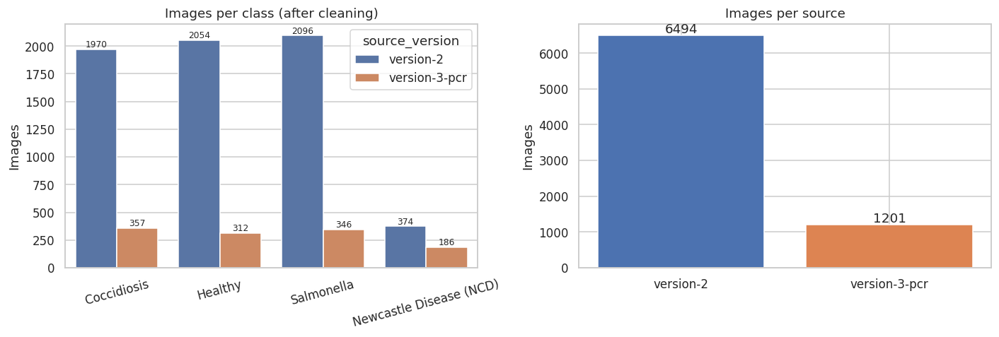

In [11]:
CLASS_PALETTE = dict(zip(CLASS_NAMES, sns.color_palette("Set2", NUM_CLASSES)))
SOURCE_PALETTE = {V2_SOURCE: "#4C72B0", PCR_SOURCE: "#DD8452"}

class_dist = (clean_df.groupby(["class", "source_version"]).size().unstack(fill_value=0)
              .reindex(CLASS_NAMES).fillna(0).astype(int))
class_dist["total"] = class_dist.sum(axis=1)
class_dist["share_%"] = (100 * class_dist["total"] / class_dist["total"].sum()).round(2)
class_dist.to_csv(os.path.join(RESULTS_DIR, "class_distribution.csv"))
display(class_dist)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_df = clean_df.assign(label=clean_df["class"].map(CLASS_DISPLAY_NAMES))
order = [CLASS_DISPLAY_NAMES[c] for c in CLASS_NAMES]
sns.countplot(data=plot_df, x="label", order=order, hue="source_version",
              palette=SOURCE_PALETTE, ax=axes[0])
axes[0].set(title="Images per class (after cleaning)", xlabel="", ylabel="Images")
for container in axes[0].containers:
    axes[0].bar_label(container, fontsize=8)
axes[0].tick_params(axis="x", rotation=15)

src_counts = clean_df["source_version"].value_counts().reindex([V2_SOURCE, PCR_SOURCE]).fillna(0)
axes[1].bar(src_counts.index, src_counts.values, color=[SOURCE_PALETTE[s] for s in src_counts.index])
axes[1].bar_label(axes[1].containers[0])
axes[1].set(title="Images per source", ylabel="Images")
fig.tight_layout()
save_figure(fig, "class_distribution.png")
plt.show()

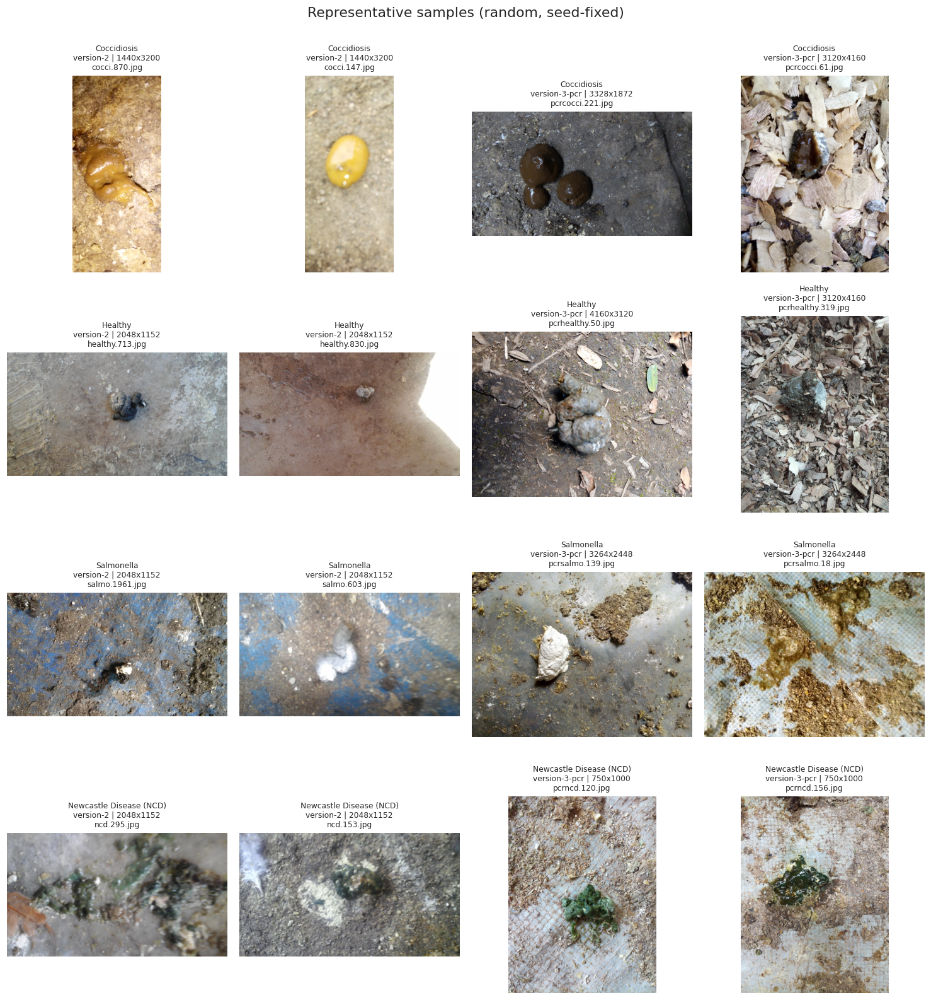

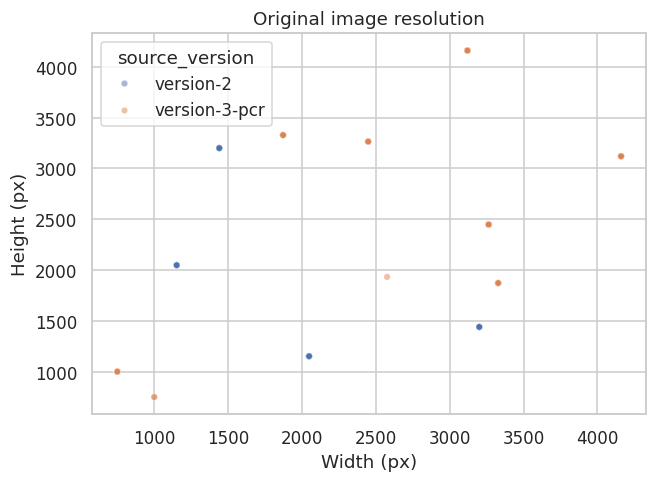

Resolution examples:


,source_version,width,height,n_images
2,version-2,2048,1152,2588
1,version-2,1440,3200,2035
5,version-2,3200,1440,895
13,version-3-pcr,3120,4160,476
3,version-2,2448,3264,370
4,version-2,3120,4160,265
10,version-3-pcr,1872,3328,229
0,version-2,1152,2048,210


In [12]:
# Sample grid: up to 2 images per (class, source), with class, source and filename.
N_PER_CELL = 2
samples = (clean_df.sample(frac=1.0, random_state=SEED)
           .groupby(["class", "source_version"], sort=False).head(N_PER_CELL))
samples["class_order"] = samples["class"].map(CLASS_TO_INDEX)
samples = samples.sort_values(["class_order", "source_version"]).reset_index(drop=True)

n_cols = 4
n_rows = int(np.ceil(len(samples) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 3.6 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax in axes:
    ax.axis("off")
for ax, (_, r) in zip(axes, samples.iterrows()):
    with Image.open(r["filepath"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"{CLASS_DISPLAY_NAMES[r['class']]}\n{r['source_version']} | {r['width']}x{r['height']}\n"
                 f"{r['filename'][:28]}", fontsize=8)
fig.suptitle("Representative samples (random, seed-fixed)", y=1.0)
fig.tight_layout()
save_figure(fig, "sample_grid.png")
plt.show()

# Resolution profile
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.scatterplot(data=clean_df, x="width", y="height", hue="source_version",
                palette=SOURCE_PALETTE, alpha=0.5, s=18, ax=ax)
ax.set(title="Original image resolution", xlabel="Width (px)", ylabel="Height (px)")
save_figure(fig, "image_resolutions.png")
plt.show()
print("Resolution examples:")
display(clean_df.groupby(["source_version", "width", "height"]).size().rename("n_images")
        .reset_index().sort_values("n_images", ascending=False).head(8))

## 9. Train / Validation / Test Split

The split is **stratified** and **group-aware**: whole duplicate groups (Section 7) are assigned to one split, and stratification is attempted on `class | source` first, then `class` alone if some stratum is too small. The random state is `SEED`, so the split is reproducible.

* **External mode:** Version 2 groups are split 70/15/15. All Version 3 PCR images form `external_pcr_test`. Any Version 2 image that shares a duplicate group with a PCR image is removed and recorded, otherwise it would leak the external test into training.
* **Combined mode:** all groups are split 70/15/15, stratified by class and source.

Percentages are targets. Because groups are indivisible and strata are rounded, the realised proportions can differ slightly. The final counts are printed and saved.

Afterwards the notebook asserts that no MD5 and no group appears in more than one split.

In [13]:
def stratified_group_split(frame, test_frac, val_frac, seed):
    """Assign whole groups to train/val/test with the best stratification that is feasible."""
    groups = (frame.groupby("group_id")
              .agg(cls=("class", "first"), n_cls=("class", "nunique"),
                   source=("source_version", lambda s: s.iloc[0] if s.nunique() == 1 else "mixed"))
              .reset_index())
    assert (groups["n_cls"] == 1).all(), "A split group contains several classes"

    def _split(g, frac):
        for key_cols in (["cls", "source"], ["cls"], None):
            strat = None if key_cols is None else g[key_cols].astype(str).agg("|".join, axis=1)
            try:
                a, b = train_test_split(g, test_size=frac, random_state=seed, stratify=strat)
                return a, b, "+".join(key_cols) if key_cols else "none"
            except ValueError:
                continue
        raise RuntimeError("Could not split the data; too few samples.")

    trainval, test, strat_test = _split(groups, test_frac)
    train, val, strat_val = _split(trainval, val_frac / (1.0 - test_frac))
    assignment = {**{g: "train" for g in train["group_id"]},
                  **{g: "val" for g in val["group_id"]},
                  **{g: "test" for g in test["group_id"]}}
    return frame["group_id"].map(assignment), {"test_split": strat_test, "val_split": strat_val}

manifest = clean_df.copy()
if USE_PCR_AS_EXTERNAL_TEST:
    if (manifest["source_version"] == PCR_SOURCE).sum() == 0:
        raise ValueError("USE_PCR_AS_EXTERNAL_TEST=True but no Version 3 PCR images were found.")
    pcr_groups = set(manifest.loc[manifest["source_version"] == PCR_SOURCE, "group_id"])
    leak = manifest[(manifest["source_version"] == V2_SOURCE) & manifest["group_id"].isin(pcr_groups)]
    for _, r in leak.iterrows():
        rejected_records.append({**r.to_dict(), "reason": "near_duplicate_of_external_pcr_test_image"})
    manifest = manifest.drop(leak.index)
    print(f"Version 2 images removed because they duplicate a PCR test image: {len(leak)}")

    v2_mask = manifest["source_version"] == V2_SOURCE
    manifest.loc[v2_mask, "split"], STRATIFICATION = stratified_group_split(
        manifest[v2_mask], TEST_FRAC, VAL_FRAC, SEED)
    manifest.loc[~v2_mask, "split"] = "external_pcr_test"
else:
    manifest["split"], STRATIFICATION = stratified_group_split(manifest, TEST_FRAC, VAL_FRAC, SEED)

assert manifest["split"].notna().all()
print("Stratification used:", STRATIFICATION)

# ---- Leakage checks ----
split_names = sorted(manifest["split"].unique())
for i, a in enumerate(split_names):
    for b in split_names[i + 1:]:
        A, B = manifest[manifest["split"] == a], manifest[manifest["split"] == b]
        assert not set(A["md5"]) & set(B["md5"]), f"MD5 overlap between {a} and {b}"
        assert not set(A["group_id"]) & set(B["group_id"]), f"Group overlap between {a} and {b}"
print("Leakage checks passed: no MD5 or duplicate group is shared between splits.")

train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
val_df = manifest[manifest["split"] == "val"].reset_index(drop=True)
test_df = manifest[manifest["split"] == "test"].reset_index(drop=True)
if USE_PCR_AS_EXTERNAL_TEST:
    pcr_eval_df = manifest[manifest["split"] == "external_pcr_test"].reset_index(drop=True)
    PCR_EVAL_IS_EXTERNAL = True
    PCR_EVAL_LABEL = "External PCR evaluation (Version 3, never used for training or model selection)"
else:
    pcr_eval_df = test_df[test_df["source_version"] == PCR_SOURCE].reset_index(drop=True)
    PCR_EVAL_IS_EXTERNAL = False
    PCR_EVAL_LABEL = ("Additional PCR sub-group evaluation (Version 3 images inside the held-out test split). "
                      "NOT an external test: other Version 3 images were used for training.")

split_summary = (manifest.groupby(["split", "source_version", "class"]).size()
                 .unstack("class", fill_value=0).reindex(columns=CLASS_NAMES, fill_value=0))
split_summary["total"] = split_summary.sum(axis=1)
display(split_summary)
totals = manifest["split"].value_counts()
dev_total = len(train_df) + len(val_df) + len(test_df)
for name in ["train", "val", "test"]:
    print(f"{name:>5}: {totals.get(name, 0):6d} images ({100 * totals.get(name, 0) / dev_total:5.1f}% of train+val+test)")
print(f"PCR evaluation set: {len(pcr_eval_df)} images | {PCR_EVAL_LABEL}")

split_summary.to_csv(os.path.join(RESULTS_DIR, "split_summary.csv"))
manifest[MANIFEST_COLUMNS + ["split"]].to_csv(os.path.join(RESULTS_DIR, "dataset_manifest.csv"), index=False)
rejected_df = save_rejected()

Version 2 images removed because they duplicate a PCR test image: 0
Stratification used: {'test_split': 'cls+source', 'val_split': 'cls+source'}
Leakage checks passed: no MD5 or duplicate group is shared between splits.


,class,Coccidiosis,Healthy,Salmonella,NCD,total
split,source_version,,,,,
external_pcr_test,version-3-pcr,357,312,346,186,1201
test,version-2,296,308,314,56,974
train,version-2,1378,1440,1467,262,4547
val,version-2,296,306,315,56,973


train:   4547 images ( 70.0% of train+val+test)
  val:    973 images ( 15.0% of train+val+test)
 test:    974 images ( 15.0% of train+val+test)
PCR evaluation set: 1201 images | External PCR evaluation (Version 3, never used for training or model selection)


### Class imbalance and class weights

Class weights are computed on the **training split only** with scikit-learn's `balanced` formula (`n_samples / (n_classes * n_class_samples)`). They are applied only if the ratio between the largest and smallest training class exceeds `IMBALANCE_THRESHOLD`. Oversampling is not used: it duplicates images, which inflates the effective weight of a few photos and interacts badly with augmentation.

In [14]:
train_counts = train_df["class"].value_counts().reindex(CLASS_NAMES, fill_value=0)
if (train_counts == 0).any():
    raise ValueError(f"Some classes are missing from the training split: {train_counts.to_dict()}")
imbalance_ratio = float(train_counts.max() / train_counts.min())
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["class_id"].values)
USE_CLASS_WEIGHTS = imbalance_ratio > IMBALANCE_THRESHOLD
CLASS_WEIGHT_DICT = {i: float(w) for i, w in enumerate(weights)} if USE_CLASS_WEIGHTS else None

save_json({"train_class_counts": train_counts.to_dict(), "imbalance_ratio_max_over_min": imbalance_ratio,
           "threshold": IMBALANCE_THRESHOLD, "class_weights_used": USE_CLASS_WEIGHTS,
           "class_weights": {c: float(w) for c, w in zip(CLASS_NAMES, weights)}},
          os.path.join(RESULTS_DIR, "class_weights.json"))
print("Training class counts:", train_counts.to_dict())
print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f} -> class weights "
      f"{'USED' if USE_CLASS_WEIGHTS else 'not used'}")
print({c: round(float(w), 3) for c, w in zip(CLASS_NAMES, weights)})

Training class counts: {'Coccidiosis': 1378, 'Healthy': 1440, 'Salmonella': 1467, 'NCD': 262}
Imbalance ratio (max/min): 5.60 -> class weights USED
{'Coccidiosis': 0.825, 'Healthy': 0.789, 'Salmonella': 0.775, 'NCD': 4.339}


## 10. Data Pipeline

`tf.data` pipeline, shared by training, evaluation, Grad-CAM and inference so every path sees identical preprocessing:

1. Read bytes and decode with `tf.io.decode_image(channels=3)`. Grayscale, RGBA and palette images become RGB.
2. Resize to `IMG_SIZE` (bilinear with antialiasing), round to `uint8`. Note: this resize does not preserve aspect ratio.
3. Cache the `uint8` tensors in RAM (optional).
4. Training only: shuffle (seeded) and augment.
5. Cast to float and apply `tf.keras.applications.resnet50.preprocess_input` (RGB to BGR, subtract ImageNet channel means, no scaling), which is exactly what the ImageNet ResNet50 weights expect.

Preprocessing is **outside** the model, so the saved model expects already-preprocessed input. This avoids `Lambda` layers, which do not reload safely from `.keras` files. The inference functions in Section 21 apply the same steps.

In [15]:
AUTOTUNE = tf.data.AUTOTUNE
preprocess_input = keras.applications.resnet50.preprocess_input   # == tf.keras.applications.resnet50.preprocess_input

def load_image_uint8(path):
    """Path -> (H, W, 3) uint8 tensor at IMG_SIZE. Used everywhere, including inference."""
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return resize_uint8(img)

def resize_uint8(img):
    img = tf.ensure_shape(img, [None, None, 3])
    img = tf.image.resize(tf.cast(img, tf.float32), IMG_SIZE, method="bilinear", antialias=True)
    return tf.cast(tf.clip_by_value(tf.round(img), 0.0, 255.0), tf.uint8)

def to_model_input(img_uint8):
    """uint8 image(s) -> float32 ResNet50-preprocessed tensor."""
    return preprocess_input(tf.cast(img_uint8, tf.float32))

# Quick check on one image
_x = load_image_uint8(train_df["filepath"].iloc[0])
_p = to_model_input(_x[None])
print("Loaded:", _x.shape, _x.dtype, "| model input:", _p.shape, _p.dtype,
      f"| value range after preprocess_input: [{float(tf.reduce_min(_p)):.1f}, {float(tf.reduce_max(_p)):.1f}]")

Loaded: (224, 224, 3) <dtype: 'uint8'> | model input: (1, 224, 224, 3) <dtype: 'float32'> | value range after preprocess_input: [-105.7, 137.1]


## 11. Data Augmentation

Fecal photographs are taken from above, so orientation carries no meaning, while colour and texture (blood, mucus, consistency) can carry disease information. The augmentation is therefore geometric-first and photometric-light:

| Transform | Setting | Reason |
|---|---|---|
| `RandomFlip` | horizontal and vertical | Top-down photos have no canonical orientation |
| `RandomRotation` | +/- about 29 degrees, reflect fill | Same; reflect fill avoids black corners |
| `RandomZoom` | +/- 10% | Camera distance varies between photos |
| `RandomContrast` | +/- 15% | Lighting differences |
| `RandomBrightness` | +/- 10% | Lighting differences |

No hue, saturation, colour jitter, grayscale, blur or cutout: these could erase or fake the colour cues the classifier should learn. Augmentation runs on the training split only; validation, test and PCR evaluation are deterministic.

Batches: train=143, val=31


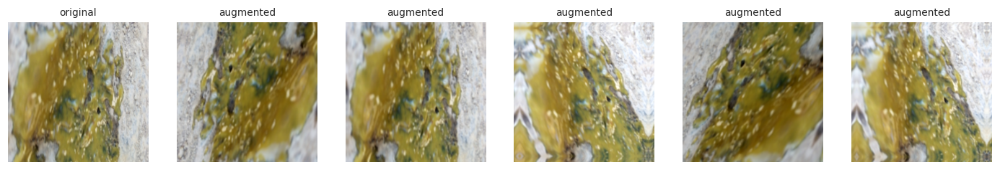

In [16]:
augmenter = keras.Sequential([
    keras.layers.RandomFlip(AUGMENTATION["flip"], seed=SEED),
    keras.layers.RandomRotation(AUGMENTATION["rotation_factor"], fill_mode="reflect", seed=SEED),
    keras.layers.RandomZoom(AUGMENTATION["zoom_factor"], fill_mode="reflect", seed=SEED),
    keras.layers.RandomContrast(AUGMENTATION["contrast_factor"], seed=SEED),
    keras.layers.RandomBrightness(AUGMENTATION["brightness_factor"], value_range=(0, 255), seed=SEED),
], name="augmentation")

def augment(img_uint8):
    x = augmenter(tf.cast(img_uint8, tf.float32), training=True)
    return tf.clip_by_value(x, 0.0, 255.0)

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["filepath"].values.astype(str),
                                             frame["class_id"].values.astype("int32")))
    ds = ds.map(lambda p, y: (load_image_uint8(p), y), num_parallel_calls=AUTOTUNE, deterministic=True)
    if CACHE_IN_MEMORY:
        ds = ds.cache()
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda x, y: (augment(x), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda x, y: (to_model_input(x), y), num_parallel_calls=AUTOTUNE, deterministic=True)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
print(f"Batches: train={len(train_df) // BATCH_SIZE + 1}, val={len(val_df) // BATCH_SIZE + 1}")

# Visual sanity check of augmentation (same image, 5 random augmentations)
_img = load_image_uint8(train_df["filepath"].iloc[0])
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(_img.numpy()); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(augment(_img).numpy().astype("uint8")); ax.set_title("augmented", fontsize=9)
for ax in axes:
    ax.axis("off")
save_figure(fig, "augmentation_examples.png")
plt.show()

## 12. Model Architecture

```
Input (224, 224, 3), already preprocessed with resnet50.preprocess_input
  -> resnet50_backbone      ResNet50, ImageNet weights, include_top=False; last activation = conv5_block3_out (7x7x2048)
  -> global_average_pooling
  -> dropout
  -> classifier             Dense(4, softmax)
```

The backbone is always called with `training=False`, so its BatchNorm layers keep their ImageNet statistics even after unfreezing. This is the standard recommendation for fine-tuning with small datasets and avoids destroying the pretrained features with noisy batch statistics.

Named layers make Grad-CAM straightforward: the backbone's output **is** the final convolutional block activation, so the Grad-CAM gradient is taken with respect to the backbone output and then passed through the three named head layers.

In [17]:
def build_model(weights=RESNET_WEIGHTS):
    base = keras.applications.ResNet50(include_top=False, weights=weights,
                                       input_shape=(*IMG_SIZE, 3))
    backbone = keras.Model(base.input, base.output, name=BACKBONE_NAME)   # rename for clarity
    backbone.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3), name="input_image")
    x = backbone(inputs, training=False)
    x = keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = keras.layers.Dropout(DROPOUT_RATE, seed=SEED, name="dropout")(x)
    outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)
    return keras.Model(inputs, outputs, name="poultry_resnet50")

set_global_seed(SEED)
model = build_model()
backbone = model.get_layer(BACKBONE_NAME)
assert backbone.layers[-1].name == LAST_CONV_LAYER, backbone.layers[-1].name
model.summary()
print(f"Backbone layers: {len(backbone.layers)} | last conv activation: {LAST_CONV_LAYER} "
      f"{tuple(backbone.output.shape)}")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "poultry_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_backbone (Functional)  │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Backbone layers: 175 | last conv activation: conv5_block3_out (None, 7, 7, 2048)


## 13. Phase 1 Training: Frozen Backbone

Only the head (dropout + dense layer, 8,196 parameters) is trained, so it learns to read ImageNet features without sending large random gradients into the pretrained backbone.

**Model selection uses validation macro-F1**, computed by a small callback after every epoch and inserted into the Keras logs so `EarlyStopping` and `ModelCheckpoint` can monitor it. `ReduceLROnPlateau` monitors validation loss, which is smoother. The best weights (by validation macro-F1) are written to `CHECKPOINT_DIR`.

In [18]:
class MacroF1Callback(keras.callbacks.Callback):
    """Computes validation macro-F1 each epoch and exposes it as logs['val_macro_f1']."""
    def __init__(self, dataset, y_true):
        super().__init__()
        self.dataset, self.y_true, self.scores = dataset, np.asarray(y_true), []

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.dataset, verbose=0)
        score = f1_score(self.y_true, probs.argmax(axis=1), average="macro",
                         labels=list(range(NUM_CLASSES)), zero_division=0)
        self.scores.append(float(score))
        if logs is not None:
            logs["val_macro_f1"] = float(score)

def make_callbacks(phase, patience, initial_best=None):
    f1_cb = MacroF1Callback(val_ds, val_df["class_id"].values)
    ckpt = keras.callbacks.ModelCheckpoint(
        BEST_WEIGHTS_PATH, monitor="val_macro_f1", mode="max", save_best_only=True,
        save_weights_only=True, initial_value_threshold=initial_best, verbose=1)
    cbs = [
        f1_cb,   # must come first so the others see val_macro_f1
        keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=patience,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=REDUCE_LR_FACTOR,
                                          patience=REDUCE_LR_PATIENCE, min_lr=MIN_LR, verbose=1),
        ckpt,
        keras.callbacks.CSVLogger(os.path.join(CHECKPOINT_DIR, f"log_{phase}.csv")),
    ]
    return cbs, f1_cb, ckpt

def history_frame(history, f1_cb, phase, epoch_offset):
    h = pd.DataFrame(history.history)
    h["val_macro_f1"] = f1_cb.scores[:len(h)]
    h.insert(0, "phase", phase)
    h.insert(0, "epoch", np.arange(1, len(h) + 1) + epoch_offset)
    return h

if os.path.exists(BEST_WEIGHTS_PATH):
    os.remove(BEST_WEIGHTS_PATH)   # never reuse a checkpoint from an earlier run

model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
              loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
cbs, f1_cb_1, ckpt_1 = make_callbacks("phase1_head", EARLY_STOPPING_PATIENCE)

t0 = time.time()
hist_1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                   class_weight=CLASS_WEIGHT_DICT, callbacks=cbs, verbose=2)
PHASE1_TIME = time.time() - t0

history_df = history_frame(hist_1, f1_cb_1, "phase1_head", 0)
BEST_PHASE1_F1 = float(max(f1_cb_1.scores))
model.load_weights(BEST_WEIGHTS_PATH)   # continue from the best phase-1 weights
print(f"Phase 1 done in {PHASE1_TIME / 60:.1f} min | best val macro-F1 = {BEST_PHASE1_F1:.4f} "
      f"(epoch {int(np.argmax(f1_cb_1.scores)) + 1})")

Epoch 1/15

Epoch 1: val_macro_f1 improved from None to 0.87355, saving model to /content/drive/MyDrive/poultry-output/checkpoints/run_20261029_191001/best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/poultry-output/checkpoints/run_20261029_191001/best.weights.h5
143/143 - 135s - 947ms/step - accuracy: 0.8271 - loss: 0.5284 - val_accuracy: 0.9209 - val_loss: 0.2085 - val_macro_f1: 0.8736 - learning_rate: 0.0010
Epoch 2/15

Epoch 2: val_macro_f1 improved from 0.87355 to 0.91634, saving model to /content/drive/MyDrive/poultry-output/checkpoints/run_20261029_191001/best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/poultry-output/checkpoints/run_20261029_191001/best.weights.h5
143/143 - 30s - 209ms/step - accuracy: 0.9175 - loss: 0.2633 - val_accuracy: 0.9424 - val_loss: 0.1497 - val_macro_f1: 0.9163 - learning_rate: 0.0010
Epoch 3/15

Epoch 3: val_macro_f1 improved from 0.91634 to 0.92332, saving model to /content/drive/MyDrive/poultry-outpu

## 14. Phase 2: Fine-Tuning

Unfreeze only the layers whose names start with `FINE_TUNE_STAGES` (default: `conv5_`, the last residual stage, about 15M parameters). Lower stages stay frozen because they encode generic edges and textures that transfer well, and fine-tuning them on a few thousand images mostly adds overfitting risk. BatchNorm layers stay frozen for the reason given in Section 12.

The learning rate is 100x smaller than in phase 1 (AdamW, `1e-5` by default). The checkpoint only overwrites the phase-1 weights if validation macro-F1 actually improves, so phase 2 cannot make the final model worse on validation.

In [19]:
BEST_EPOCH_PHASE = "phase1_head"
if EPOCHS_FINE > 0:
    backbone = model.get_layer(BACKBONE_NAME)
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = (layer.name.startswith(tuple(FINE_TUNE_STAGES))
                           and not isinstance(layer, keras.layers.BatchNormalization))
    n_trainable_layers = sum(l.trainable and len(l.weights) > 0 for l in backbone.layers)
    n_trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    print(f"Unfrozen backbone layers with weights: {n_trainable_layers} | "
          f"trainable parameters: {n_trainable_params:,}")

    model.compile(optimizer=keras.optimizers.AdamW(LEARNING_RATE_FINE, weight_decay=WEIGHT_DECAY_FINE),
                  loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
    cbs, f1_cb_2, ckpt_2 = make_callbacks("phase2_finetune", EARLY_STOPPING_PATIENCE,
                                          initial_best=BEST_PHASE1_F1)
    t0 = time.time()
    hist_2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE,
                       class_weight=CLASS_WEIGHT_DICT, callbacks=cbs, verbose=2)
    PHASE2_TIME = time.time() - t0
    history_df = pd.concat([history_df, history_frame(hist_2, f1_cb_2, "phase2_finetune", len(history_df))],
                           ignore_index=True)
    if max(f1_cb_2.scores) > BEST_PHASE1_F1:
        BEST_EPOCH_PHASE = "phase2_finetune"
    print(f"Phase 2 done in {PHASE2_TIME / 60:.1f} min | best phase-2 val macro-F1 = {max(f1_cb_2.scores):.4f}")
else:
    PHASE2_TIME = 0.0
    print("EPOCHS_FINE = 0: fine-tuning skipped.")

# Restore the single best checkpoint across both phases.
model.load_weights(BEST_WEIGHTS_PATH)
best_idx = int(history_df[history_df["phase"] == BEST_EPOCH_PHASE]["val_macro_f1"].idxmax())
BEST_EPOCH = int(history_df.loc[best_idx, "epoch"])
BEST_VAL_MACRO_F1 = float(history_df.loc[best_idx, "val_macro_f1"])
history_df.to_csv(os.path.join(RESULTS_DIR, "training_history.csv"), index=False)
print(f"Best checkpoint: global epoch {BEST_EPOCH} ({BEST_EPOCH_PHASE}), val macro-F1 = {BEST_VAL_MACRO_F1:.4f}")

Unfrozen backbone layers with weights: 10 | trainable parameters: 14,961,668
Epoch 1/20

Epoch 1: val_macro_f1 did not improve from 0.95272
143/143 - 66s - 464ms/step - accuracy: 0.9580 - loss: 0.1431 - val_accuracy: 0.9599 - val_loss: 0.1168 - val_macro_f1: 0.9325 - learning_rate: 1.0000e-05
Epoch 2/20

Epoch 2: val_macro_f1 did not improve from 0.95272
143/143 - 33s - 234ms/step - accuracy: 0.9664 - loss: 0.0939 - val_accuracy: 0.9692 - val_loss: 0.0776 - val_macro_f1: 0.9516 - learning_rate: 1.0000e-05
Epoch 3/20

Epoch 3: val_macro_f1 improved from 0.95272 to 0.97243, saving model to /content/drive/MyDrive/poultry-output/checkpoints/run_20261029_191001/best.weights.h5

Epoch 3: finished saving model to /content/drive/MyDrive/poultry-output/checkpoints/run_20261029_191001/best.weights.h5
143/143 - 33s - 234ms/step - accuracy: 0.9697 - loss: 0.0864 - val_accuracy: 0.9784 - val_loss: 0.0736 - val_macro_f1: 0.9724 - learning_rate: 1.0000e-05
Epoch 4/20

Epoch 4: val_macro_f1 did not im

## 15. Training Curves

Loss, accuracy and validation macro-F1 across both phases. The dashed line marks the start of fine-tuning and the star marks the selected checkpoint. A widening gap between training and validation loss after the dashed line is the usual sign of overfitting during fine-tuning.

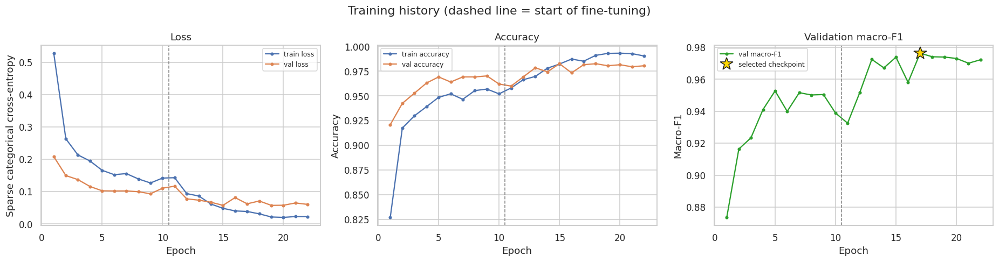

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ep = history_df["epoch"]
phase2_start = history_df.loc[history_df["phase"] == "phase2_finetune", "epoch"].min()

axes[0].plot(ep, history_df["loss"], "o-", ms=3, label="train loss")
axes[0].plot(ep, history_df["val_loss"], "o-", ms=3, label="val loss")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Sparse categorical cross-entropy")
axes[1].plot(ep, history_df["accuracy"], "o-", ms=3, label="train accuracy")
axes[1].plot(ep, history_df["val_accuracy"], "o-", ms=3, label="val accuracy")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[2].plot(ep, history_df["val_macro_f1"], "o-", ms=3, color="tab:green", label="val macro-F1")
axes[2].plot(BEST_EPOCH, BEST_VAL_MACRO_F1, "*", ms=16, color="gold", mec="k", label="selected checkpoint")
axes[2].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for ax in axes:
    if pd.notna(phase2_start):
        ax.axvline(phase2_start - 0.5, ls="--", c="grey", lw=1)
    ax.legend(fontsize=8)
fig.suptitle("Training history (dashed line = start of fine-tuning)")
fig.tight_layout()
save_figure(fig, "training_history.png")
plt.show()

## 16. Final Evaluation (held-out test set)

The best checkpoint is evaluated on the test split **once**. The predictions are cached, so re-running this cell does not re-predict; tuning decisions must never be based on these numbers.

**Why macro-F1 matters here.** Accuracy is dominated by the largest classes. In a disease setting the costly mistakes are usually in the smaller classes (for example, a Newcastle Disease case labelled Healthy). Macro-F1 averages the per-class F1 scores with equal weight, so a model that ignores a small class is penalised even if its accuracy looks good. Weighted-F1 is reported alongside it for comparison, as are per-class precision (how trustworthy a positive prediction is) and recall (how many true cases are caught).

ROC-AUC is computed one-vs-rest and only when every class is present in the evaluated set; otherwise it is reported per class where defined. Log loss measures calibration of the predicted probabilities, not just the ranking.

In [21]:
LABELS = list(range(NUM_CLASSES))

def compute_metrics(y_true, probs):
    y_true = np.asarray(y_true)
    probs = np.asarray(probs, dtype=np.float64)
    probs = probs / probs.sum(axis=1, keepdims=True)
    y_pred = probs.argmax(axis=1)
    present = sorted(set(y_true.tolist()))
    m = {
        "n_samples": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=LABELS, average="weighted", zero_division=0),
        "log_loss": log_loss(y_true, probs, labels=LABELS),
        "classes_present": [CLASS_NAMES[i] for i in present],
    }
    if len(present) < NUM_CLASSES:
        m["note"] = "Not all classes are present; macro averages include absent classes as 0 where undefined."
    y_bin = label_binarize(y_true, classes=LABELS)
    per_auc, per_ap = {}, {}
    for i, c in enumerate(CLASS_NAMES):
        if 0 < y_bin[:, i].sum() < len(y_true):
            per_auc[c] = roc_auc_score(y_bin[:, i], probs[:, i])
            per_ap[c] = average_precision_score(y_bin[:, i], probs[:, i])
        else:
            per_auc[c] = per_ap[c] = None
    m["roc_auc_ovr_macro"] = (roc_auc_score(y_true, probs, multi_class="ovr", average="macro", labels=LABELS)
                              if len(present) == NUM_CLASSES else None)
    m["roc_auc_per_class"], m["average_precision_per_class"] = per_auc, per_ap
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    m["per_class"] = {c: {"precision": p[i], "recall": r[i], "f1": f[i], "support": int(s[i])}
                      for i, c in enumerate(CLASS_NAMES)}
    m["confusion_matrix"] = confusion_matrix(y_true, y_pred, labels=LABELS).tolist()
    return m

def report_frame(m):
    rep = pd.DataFrame(m["per_class"]).T
    rep["roc_auc_ovr"] = pd.Series(m["roc_auc_per_class"])
    rep["average_precision"] = pd.Series(m["average_precision_per_class"])
    rep.loc["macro avg"] = [m["macro_precision"], m["macro_recall"], m["macro_f1"], m["n_samples"],
                            m["roc_auc_ovr_macro"], np.nan]
    rep.loc["accuracy"] = [np.nan, np.nan, m["accuracy"], m["n_samples"], np.nan, np.nan]
    rep["support"] = rep["support"].astype(int)
    return rep

def plot_confusion(cm, title, filename, normalize=False):
    cm = np.asarray(cm, dtype=float)
    data = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) if normalize else cm
    labels = [CLASS_DISPLAY_NAMES[c].replace(" (NCD)", "\n(NCD)") for c in CLASS_NAMES]
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    sns.heatmap(data, annot=True, fmt=".2f" if normalize else ".0f", cmap="Blues", cbar=True,
                xticklabels=labels, yticklabels=labels, vmin=0, vmax=1 if normalize else None, ax=ax)
    ax.set(xlabel="Predicted", ylabel="True", title=title)
    plt.setp(ax.get_yticklabels(), rotation=0)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()

def plot_roc_pr(y_true, probs, prefix, title_suffix):
    y_bin = label_binarize(y_true, classes=LABELS)
    for kind in ("roc", "pr"):
        fig, ax = plt.subplots(figsize=(6.2, 5.2))
        for i, c in enumerate(CLASS_NAMES):
            if not (0 < y_bin[:, i].sum() < len(y_true)):
                continue
            if kind == "roc":
                fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
                ax.plot(fpr, tpr, color=CLASS_PALETTE[c],
                        label=f"{c} (AUC={roc_auc_score(y_bin[:, i], probs[:, i]):.3f})")
            else:
                prec, rec, _ = precision_recall_curve(y_bin[:, i], probs[:, i])
                ax.plot(rec, prec, color=CLASS_PALETTE[c],
                        label=f"{c} (AP={average_precision_score(y_bin[:, i], probs[:, i]):.3f})")
        if kind == "roc":
            ax.plot([0, 1], [0, 1], "k--", lw=0.8)
            ax.set(xlabel="False positive rate", ylabel="True positive rate",
                   title=f"ROC one-vs-rest ({title_suffix})")
            fname = f"{prefix}roc_curves.png"
        else:
            ax.set(xlabel="Recall", ylabel="Precision", title=f"Precision-recall ({title_suffix})")
            fname = f"{prefix}precision_recall_curves.png"
        ax.legend(fontsize=8, loc="lower right" if kind == "roc" else "lower left")
        fig.tight_layout()
        save_figure(fig, fname)
        plt.show()

def predictions_frame(frame, probs):
    out = frame[["filepath", "relpath", "source_version", "group_id"]].copy()
    out["true_class"] = frame["class"].values
    out["predicted_class"] = [CLASS_NAMES[i] for i in probs.argmax(axis=1)]
    out["confidence"] = probs.max(axis=1)
    out["correct"] = out["true_class"] == out["predicted_class"]
    for i, c in enumerate(CLASS_NAMES):
        out[f"prob_{c}"] = probs[:, i]
    return out

Test set predicted once (974 images).

Test set (Version 2 held-out)
           n_samples: 974
            accuracy: 0.9671
     macro_precision: 0.9656
        macro_recall: 0.9450
            macro_f1: 0.9545
         weighted_f1: 0.9669
            log_loss: 0.1021
   roc_auc_ovr_macro: 0.9981


,precision,recall,f1,support,roc_auc_ovr,average_precision
Coccidiosis,0.9610,1.0000,0.9801,296,0.9999,0.9997
Healthy,0.9708,0.9708,0.9708,308,0.9981,0.9955
Salmonella,0.9708,0.9522,0.9614,314,0.9970,0.9947
NCD,0.9600,0.8571,0.9057,56,0.9975,0.9699
macro avg,0.9656,0.9450,0.9545,974,0.9981,NaN
accuracy,NaN,NaN,0.9671,974,NaN,NaN


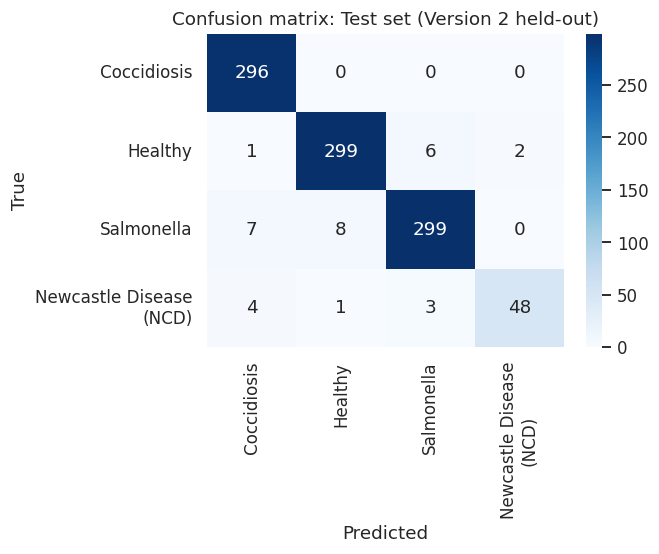

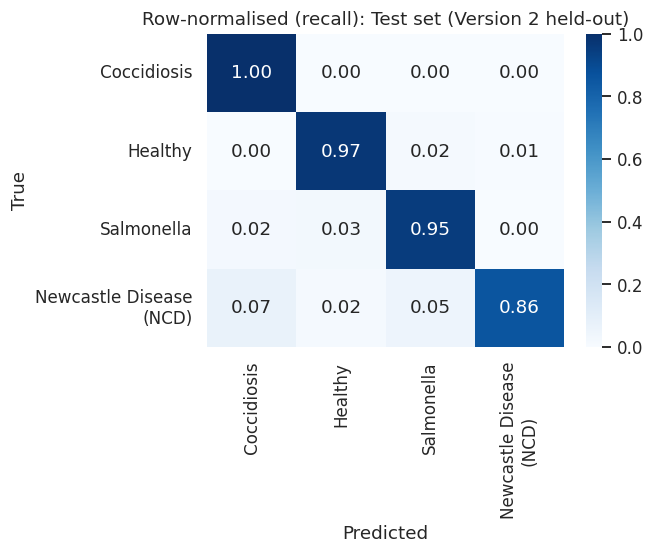

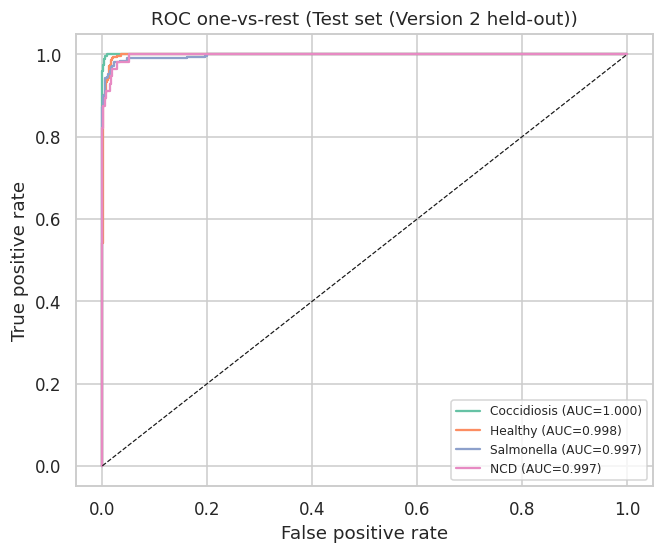

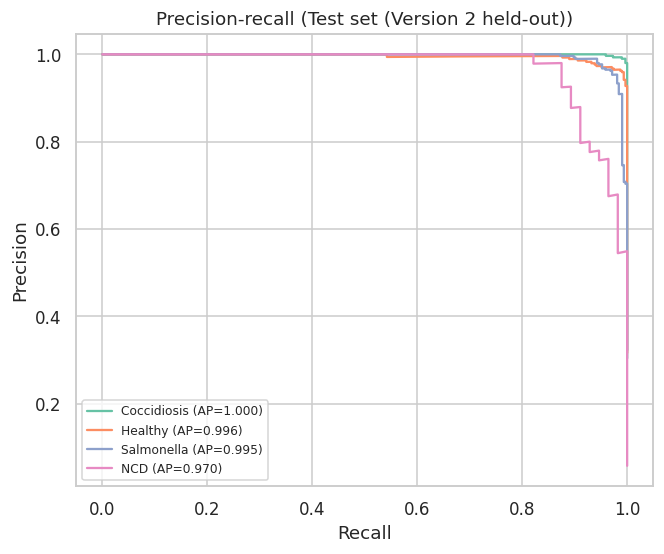

In [22]:
# ---- Single evaluation of the held-out test set ----
if "TEST_PROBS" not in globals():
    TEST_PROBS = model.predict(make_dataset(test_df), verbose=0)
    print(f"Test set predicted once ({len(test_df)} images).")
else:
    print("Re-using cached test predictions (the test set is evaluated only once).")

y_test = test_df["class_id"].values
TEST_METRICS = compute_metrics(y_test, TEST_PROBS)
test_pred_df = predictions_frame(test_df, TEST_PROBS)
test_pred_df.to_csv(os.path.join(RESULTS_DIR, "test_predictions.csv"), index=False)
test_report = report_frame(TEST_METRICS)
test_report.to_csv(os.path.join(RESULTS_DIR, "classification_report.csv"))

test_title = "Test set (Version 2 held-out)" if USE_PCR_AS_EXTERNAL_TEST else "Test set (Version 2 + 3 held-out)"
print(f"\n{test_title}")
for k in ["n_samples", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
          "log_loss", "roc_auc_ovr_macro"]:
    v = TEST_METRICS[k]
    print(f"  {k:>18}: {v:.4f}" if isinstance(v, float) else f"  {k:>18}: {v}")
display(test_report.round(4))

# Per-source breakdown of the main test (useful in combined mode)
if test_df["source_version"].nunique() > 1:
    print("Macro-F1 by source inside the test split:")
    for src, g in test_pred_df.groupby("source_version"):
        idx = g.index.values
        print(f"  {src}: n={len(g)}, macro-F1={compute_metrics(y_test[idx], TEST_PROBS[idx])['macro_f1']:.4f}")

plot_confusion(TEST_METRICS["confusion_matrix"], f"Confusion matrix: {test_title}", "confusion_matrix.png")
plot_confusion(TEST_METRICS["confusion_matrix"], f"Row-normalised (recall): {test_title}",
               "normalized_confusion_matrix.png", normalize=True)
plot_roc_pr(y_test, TEST_PROBS, "", test_title)

METRICS = {"experiment_mode": EXPERIMENT_CONFIG["experiment_mode"],
           "best_epoch": BEST_EPOCH, "best_epoch_phase": BEST_EPOCH_PHASE,
           "best_val_macro_f1": BEST_VAL_MACRO_F1, "test": TEST_METRICS}
save_json(METRICS, os.path.join(RESULTS_DIR, "metrics.json"))

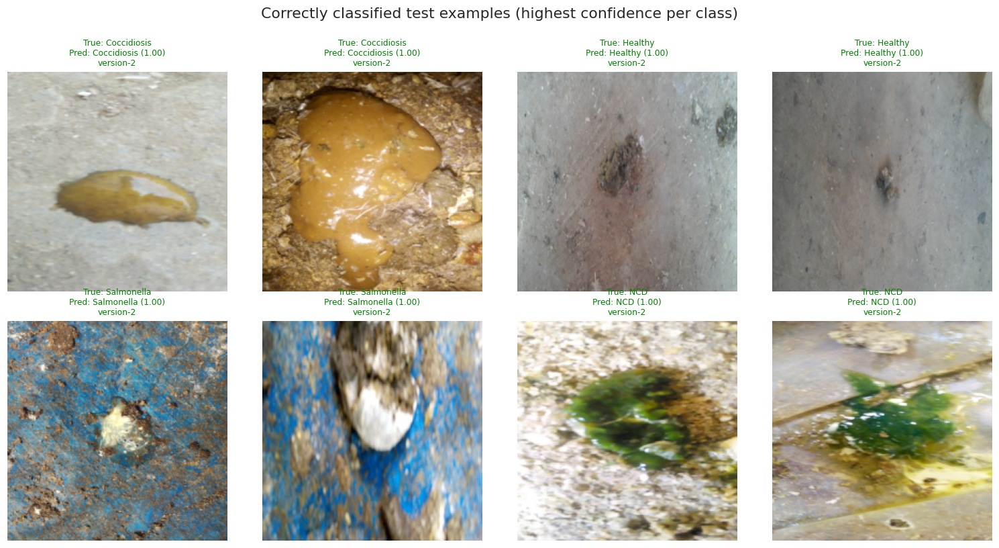

Correct: 942 / 974 | misclassified: 32


In [23]:
# ---- Correctly classified examples: highest-confidence correct prediction per class ----
def show_grid(rows, title, filename, n_cols=4):
    n = len(rows)
    if n == 0:
        print(f"{title}: nothing to show.")
        return
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.7 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (_, r) in zip(axes, rows.iterrows()):
        ax.imshow(load_image_uint8(r["filepath"]).numpy())
        color = "green" if r["correct"] else "red"
        ax.set_title(f"True: {r['true_class']}\nPred: {r['predicted_class']} ({r['confidence']:.2f})\n"
                     f"{r['source_version']}", fontsize=8, color=color)
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()

correct_examples = (test_pred_df[test_pred_df["correct"]].sort_values("confidence", ascending=False)
                    .groupby("true_class", sort=False).head(2))
correct_examples = correct_examples.assign(o=correct_examples["true_class"].map(CLASS_TO_INDEX)).sort_values("o")
show_grid(correct_examples, "Correctly classified test examples (highest confidence per class)",
          "correct_examples.png")
print(f"Correct: {int(test_pred_df['correct'].sum())} / {len(test_pred_df)} | "
      f"misclassified: {int((~test_pred_df['correct']).sum())}")

## 17. Error Analysis

All misclassified test images, sorted by confidence. **High-confidence errors** are the most informative: they point to label noise, look-alike classes, acquisition artefacts (background, lighting, feathers, litter), or duplicate-like images the audit did not catch. They are shown, not hidden.

Most frequent confusions (true -> predicted):


,true_class,predicted_class,count
0,Salmonella,Healthy,8
1,Salmonella,Coccidiosis,7
2,Healthy,Salmonella,6
3,NCD,Coccidiosis,4
4,NCD,Salmonella,3
5,Healthy,NCD,2
6,Healthy,Coccidiosis,1
7,NCD,Healthy,1


Highest-confidence errors:


,relpath,source_version,true_class,predicted_class,confidence
735,version-2/salmo/salmo.146.jpg,version-2,Salmonella,Healthy,0.999932
825,version-2/salmo/salmo.2016.jpg,version-2,Salmonella,Coccidiosis,0.999903
827,version-2/salmo/salmo.2021.jpg,version-2,Salmonella,Coccidiosis,0.999745
311,version-2/healthy/healthy.1104.jpg,version-2,Healthy,Salmonella,0.988217
717,version-2/salmo/salmo.1356.jpg,version-2,Salmonella,Healthy,0.980773
637,version-2/ncd/ncd.30.jpg,version-2,NCD,Coccidiosis,0.974390
708,version-2/salmo/salmo.1291.jpg,version-2,Salmonella,Healthy,0.969494
652,version-2/ncd/ncd.5.jpg,version-2,NCD,Coccidiosis,0.968310
496,version-2/healthy/healthy.34.jpg,version-2,Healthy,Salmonella,0.961725
684,version-2/salmo/salmo.1128.jpg,version-2,Salmonella,Healthy,0.953273


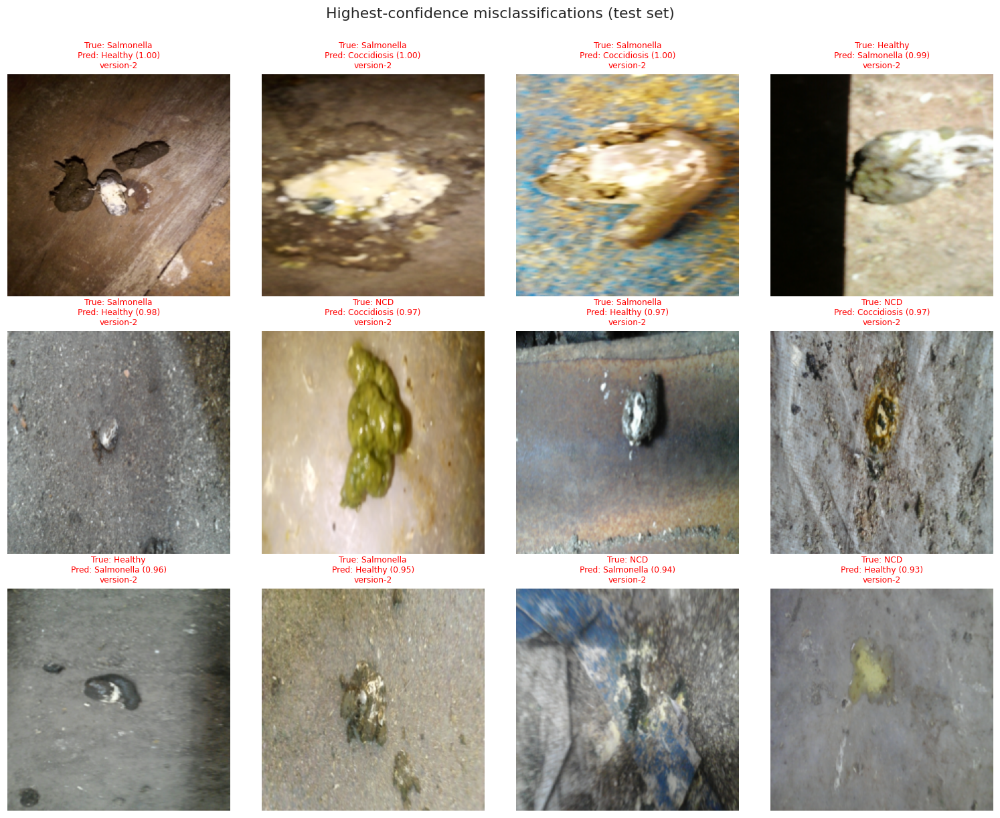

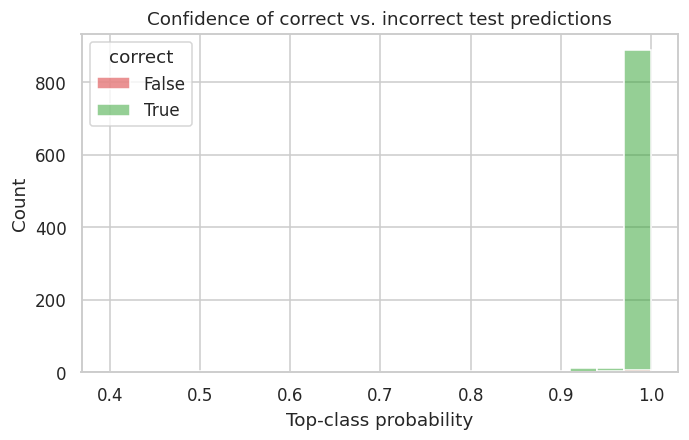

In [24]:
errors = test_pred_df[~test_pred_df["correct"]].sort_values("confidence", ascending=False)
errors.to_csv(os.path.join(RESULTS_DIR, "test_errors.csv"), index=False)

if len(errors):
    print("Most frequent confusions (true -> predicted):")
    display(errors.groupby(["true_class", "predicted_class"]).size().sort_values(ascending=False)
            .rename("count").reset_index())
    print("Highest-confidence errors:")
    display(errors[["relpath", "source_version", "true_class", "predicted_class", "confidence"]].head(15))
    show_grid(errors.head(12), "Highest-confidence misclassifications (test set)", "error_grid.png")

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(data=test_pred_df, x="confidence", hue="correct", bins=20, multiple="layer",
                 palette={True: "tab:green", False: "tab:red"}, ax=ax)
    ax.set(title="Confidence of correct vs. incorrect test predictions", xlabel="Top-class probability")
    save_figure(fig, "confidence_distribution.png")
    plt.show()
else:
    print("No misclassifications on the test set. Treat this with suspicion on a small test set "
          "and check the PCR evaluation and the duplicate report.")

## 18. Grad-CAM Explainability

Grad-CAM weights the 2048 feature maps of `conv5_block3_out` (the last convolutional activation of ResNet50, 7x7) by the average gradient of the class **logit** with respect to each map. The logit (pre-softmax score) is used instead of the probability because softmax saturates near 0 and 1, which flattens gradients.

Examples: the two most confident correct predictions per class plus up to eight high-confidence errors.

**Interpretation caveat.** Grad-CAM shows which image regions influenced the score. It does not show that the model uses biologically meaningful evidence, and a plausible-looking heatmap is not validation of the model. The 7x7 resolution also makes maps coarse. Heatmaps concentrated on background, litter or image borders are a warning sign of shortcut learning.

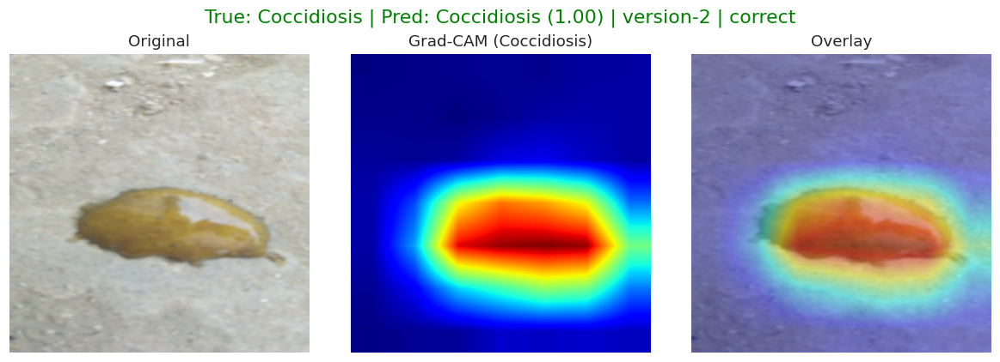

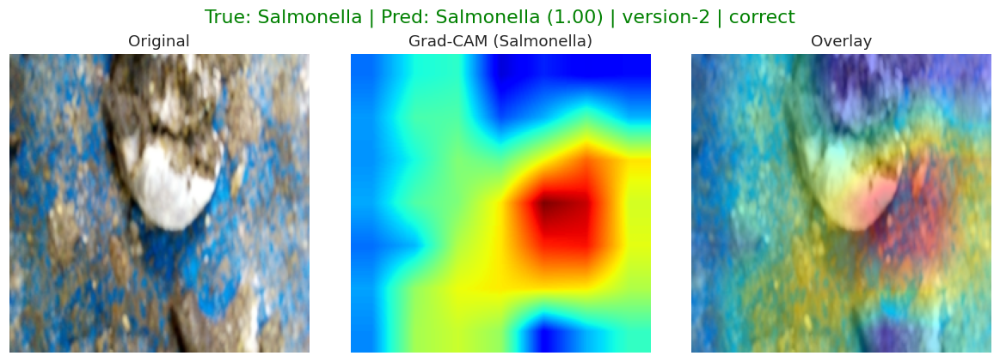

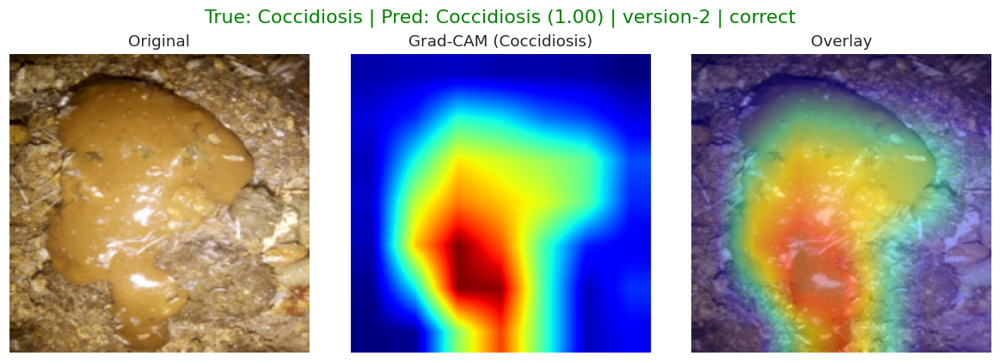

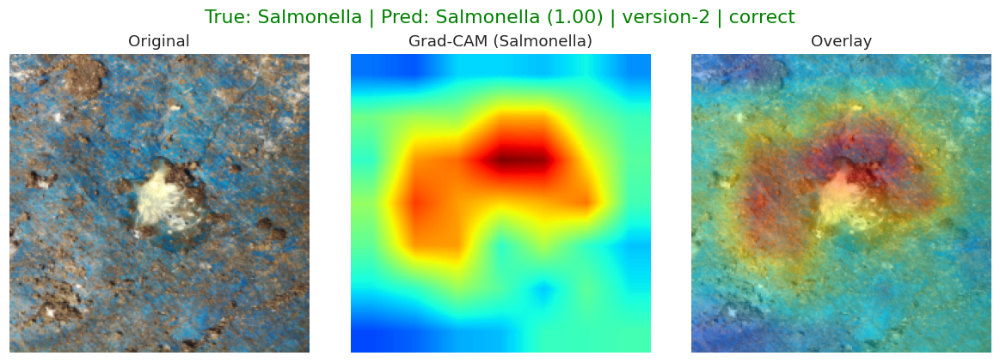

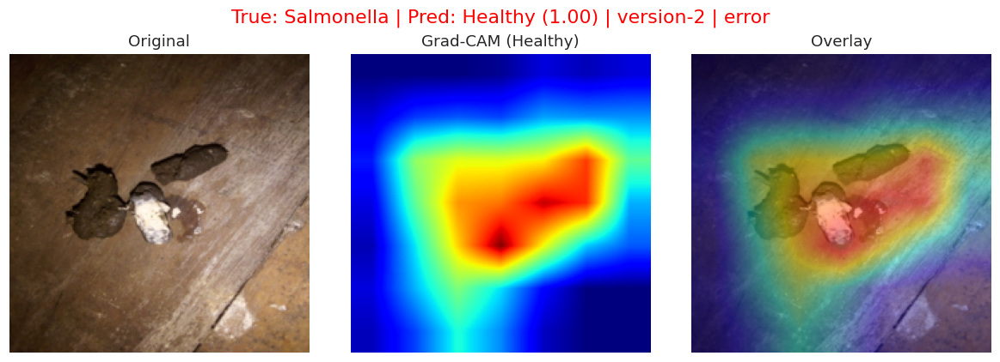

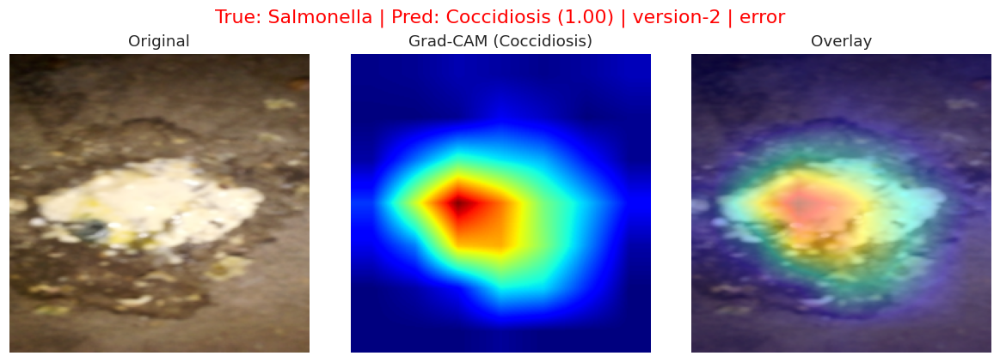

Saved 16 Grad-CAM figures to /content/drive/MyDrive/poultry-output/run_20261029_191001/gradcam (a few are displayed above).


In [25]:
def gradcam_heatmap(model, img_uint8, class_index=None):
    """Returns (heatmap in [0,1] at IMG_SIZE, class_index, probabilities)."""
    bb = model.get_layer(BACKBONE_NAME)
    gap = model.get_layer("global_average_pooling")
    clf = model.get_layer("classifier")
    x = to_model_input(tf.convert_to_tensor(img_uint8)[None])
    with tf.GradientTape() as tape:
        conv = bb(x, training=False)                       # (1, 7, 7, 2048) = conv5_block3_out
        tape.watch(conv)
        logits = tf.matmul(gap(conv), clf.kernel) + clf.bias   # dropout is identity at inference
        probs = tf.nn.softmax(logits)
        if class_index is None:
            class_index = int(tf.argmax(logits[0]))
        score = logits[:, class_index]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))           # (1, 2048)
    cam = tf.nn.relu(tf.reduce_sum(conv * weights[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMG_SIZE, method="bilinear")[..., 0]
    return cam.numpy(), class_index, probs.numpy()[0]

def overlay_heatmap(img_uint8, heatmap, alpha=0.4):
    colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    colored = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)
    return np.uint8(np.clip((1 - alpha) * img_uint8 + alpha * colored, 0, 255))

# Consistency check: the Grad-CAM forward path must reproduce model.predict
_img = load_image_uint8(test_df["filepath"].iloc[0]).numpy()
_, _, _p = gradcam_heatmap(model, _img)
assert np.allclose(_p, TEST_PROBS[0], atol=1e-3), "Grad-CAM path does not match the model output"

gc_correct = (test_pred_df[test_pred_df["correct"]].sort_values("confidence", ascending=False)
              .groupby("true_class", sort=False).head(2))
gc_errors = test_pred_df[~test_pred_df["correct"]].sort_values("confidence", ascending=False).head(8)
gc_selection = pd.concat([gc_correct.assign(kind="correct"), gc_errors.assign(kind="error")], ignore_index=True)

index_rows = []
for k, r in gc_selection.iterrows():
    img = load_image_uint8(r["filepath"]).numpy()
    heat, cls_idx, _ = gradcam_heatmap(model, img)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
    axes[0].imshow(img); axes[0].set_title("Original")
    axes[1].imshow(heat, cmap="jet", vmin=0, vmax=1); axes[1].set_title(f"Grad-CAM ({CLASS_NAMES[cls_idx]})")
    axes[2].imshow(overlay_heatmap(img, heat)); axes[2].set_title("Overlay")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"True: {r['true_class']} | Pred: {r['predicted_class']} ({r['confidence']:.2f}) | "
                 f"{r['source_version']} | {r['kind']}", color="green" if r["correct"] else "red")
    fig.tight_layout()
    out_file = os.path.join(GRADCAM_DIR, f"{k:02d}_{r['kind']}_{r['true_class']}_as_{r['predicted_class']}.png")
    fig.savefig(out_file)
    n_correct = len(gc_correct)
    if (r["kind"] == "correct" and k < 4) or (r["kind"] == "error" and k < n_correct + 2):
        plt.show()   # display a few inline, save all
    else:
        plt.close(fig)
    index_rows.append({"filepath": r["filepath"], "true_class": r["true_class"],
                       "predicted_class": r["predicted_class"], "confidence": r["confidence"],
                       "kind": r["kind"], "output_file": out_file})

gradcam_index = pd.DataFrame(index_rows)
gradcam_index.to_csv(os.path.join(GRADCAM_DIR, "gradcam_index.csv"), index=False)
print(f"Saved {len(gradcam_index)} Grad-CAM figures to {GRADCAM_DIR} (a few are displayed above).")

## 19. PCR Evaluation

Performance on Version 3 PCR-confirmed images. The printed heading states which kind of evaluation this is:

* **External mode:** every PCR image, none of which was used for training, early stopping or checkpoint selection. It measures transfer from field-labelled Version 2 images to PCR-confirmed images from a separate collection. Expect this to be lower than the internal test score; the gap itself is a useful finding.
* **Combined mode:** only the PCR images inside the held-out test split. Other PCR images were in training, so this is a sub-group analysis of the same distribution, **not** an independent or external test.

Sample sizes per class are shown because small PCR subsets give wide uncertainty; a single image can move per-class recall by several points.

External PCR evaluation (Version 3, never used for training or model selection)
Class counts: {'Coccidiosis': 357, 'Healthy': 312, 'Salmonella': 346, 'NCD': 186}
           n_samples: 1201
            accuracy: 0.7952
     macro_precision: 0.8055
        macro_recall: 0.7910
            macro_f1: 0.7945
         weighted_f1: 0.7932
            log_loss: 0.7508
   roc_auc_ovr_macro: 0.9524


,precision,recall,f1,support,roc_auc_ovr,average_precision
Coccidiosis,0.8625,0.7731,0.8154,357,0.9638,0.9320
Healthy,0.7222,0.6667,0.6933,312,0.8949,0.7776
Salmonella,0.7629,0.9393,0.8420,346,0.9659,0.9083
NCD,0.8743,0.7849,0.8272,186,0.9849,0.9320
macro avg,0.8055,0.7910,0.7945,1201,0.9524,NaN
accuracy,NaN,NaN,0.7952,1201,NaN,NaN


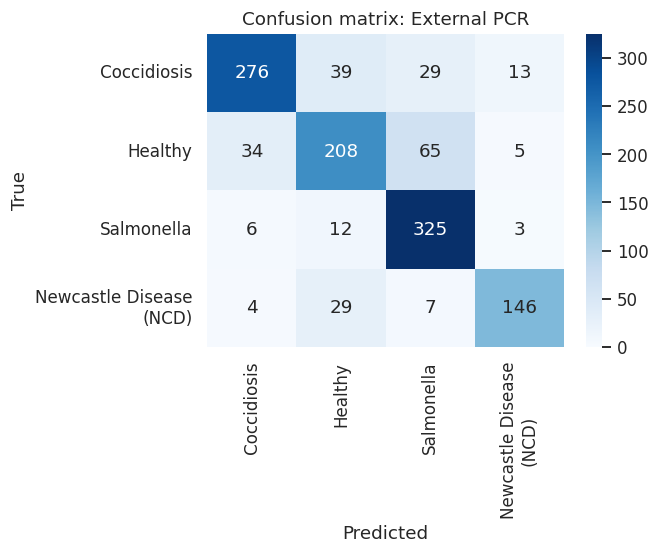

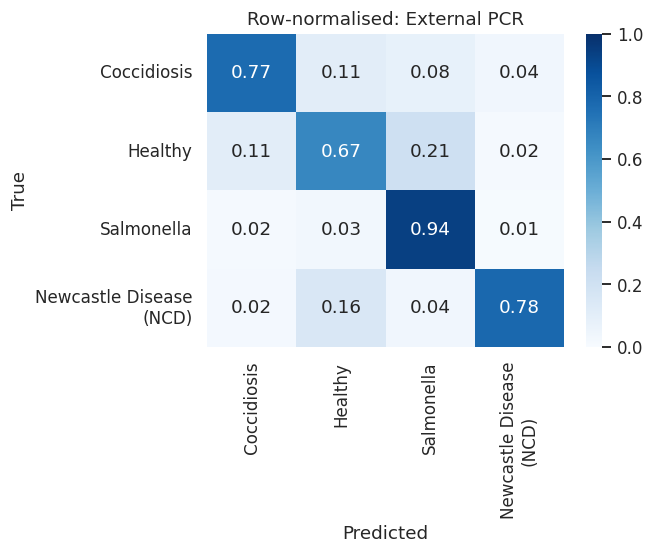

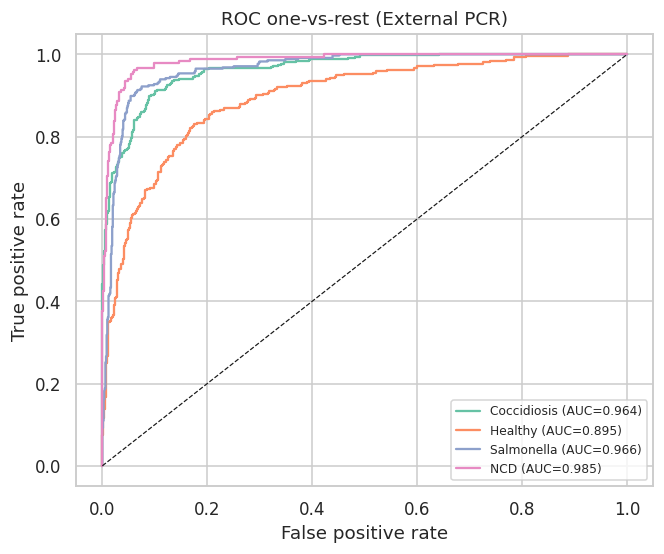

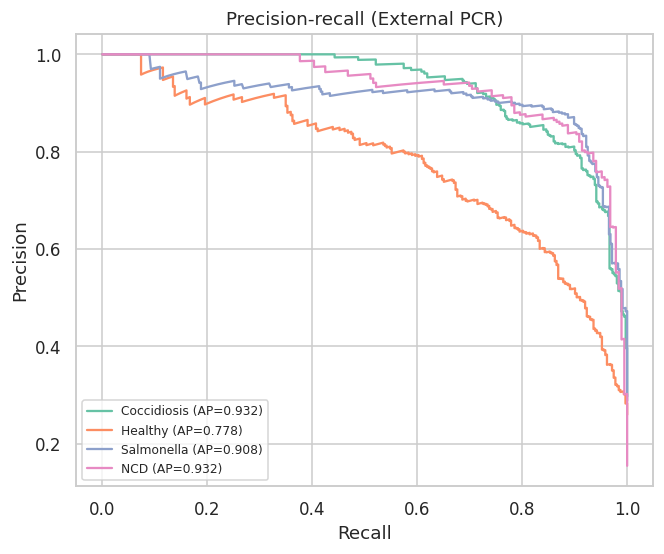

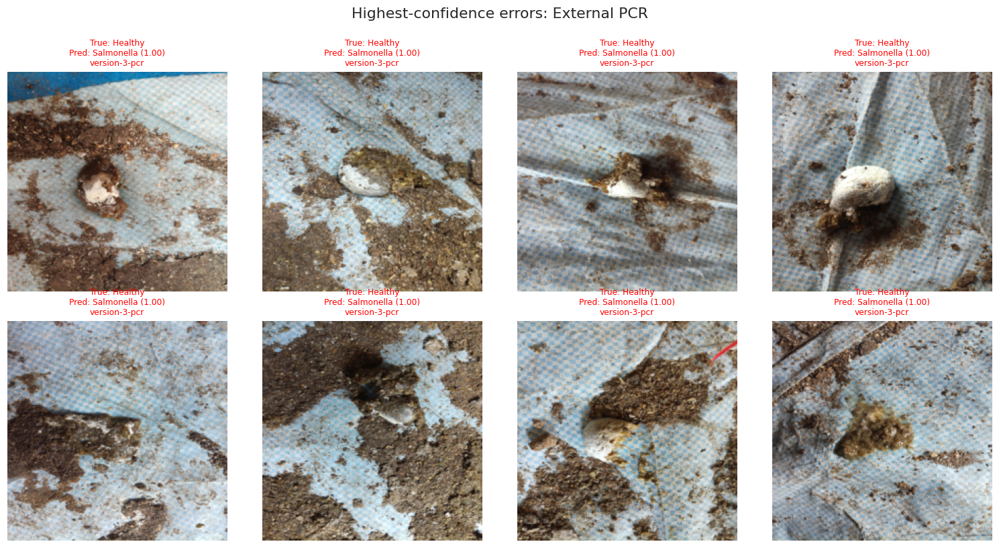

In [26]:
print(PCR_EVAL_LABEL)
if len(pcr_eval_df) == 0:
    PCR_METRICS = None
    print("No PCR images in the evaluation set; skipping.")
else:
    if PCR_EVAL_IS_EXTERNAL:
        if "PCR_PROBS" not in globals():
            PCR_PROBS = model.predict(make_dataset(pcr_eval_df), verbose=0)
    else:
        pos = test_df.index[test_df["source_version"] == PCR_SOURCE].values
        PCR_PROBS = TEST_PROBS[pos]
    y_pcr = pcr_eval_df["class_id"].values
    PCR_METRICS = compute_metrics(y_pcr, PCR_PROBS)
    PCR_METRICS["evaluation_type"] = "external_held_out" if PCR_EVAL_IS_EXTERNAL else "in_distribution_subgroup_of_test"
    PCR_METRICS["description"] = PCR_EVAL_LABEL

    pcr_pred_df = predictions_frame(pcr_eval_df, PCR_PROBS)
    pcr_pred_df.to_csv(os.path.join(RESULTS_DIR, "pcr_predictions.csv"), index=False)
    pcr_report = report_frame(PCR_METRICS)
    pcr_report.to_csv(os.path.join(RESULTS_DIR, "pcr_classification_report.csv"))

    print("Class counts:", pcr_eval_df["class"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict())
    for k in ["n_samples", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
              "log_loss", "roc_auc_ovr_macro"]:
        v = PCR_METRICS[k]
        print(f"  {k:>18}: {v:.4f}" if isinstance(v, float) else f"  {k:>18}: {v}")
    display(pcr_report.round(4))
    tag = "External PCR" if PCR_EVAL_IS_EXTERNAL else "PCR sub-group of test"
    plot_confusion(PCR_METRICS["confusion_matrix"], f"Confusion matrix: {tag}", "pcr_confusion_matrix.png")
    plot_confusion(PCR_METRICS["confusion_matrix"], f"Row-normalised: {tag}",
                   "pcr_normalized_confusion_matrix.png", normalize=True)
    if PCR_METRICS["roc_auc_ovr_macro"] is not None:
        plot_roc_pr(y_pcr, PCR_PROBS, "pcr_", tag)
    show_grid(pcr_pred_df[~pcr_pred_df["correct"]].sort_values("confidence", ascending=False).head(8),
              f"Highest-confidence errors: {tag}", "pcr_error_grid.png")

METRICS["pcr_evaluation"] = PCR_METRICS
save_json(METRICS, os.path.join(RESULTS_DIR, "metrics.json"))

## 20. Model Export

Saved artefacts:

* `models/poultry_resnet50.keras` (modern Keras format, architecture + weights)
* `models/poultry_resnet50_savedmodel/` (TensorFlow SavedModel for TF Serving / TFLite conversion)
* `models/class_names.json` and `models/model_config.json` (everything needed to reproduce preprocessing and decode outputs)

The exported model is a fresh, **uncompiled** copy of the architecture loaded with the best checkpoint weights, so the file contains no optimizer state (roughly half the size). The `.keras` file is then reloaded in isolation and its predictions compared against the trained in-memory model, which proves the saved artefact is self-sufficient.

In [27]:
# Clean inference copy: same architecture, best weights, no optimizer state.
export_model = build_model(weights=None)
export_model.load_weights(BEST_WEIGHTS_PATH)
export_model.save(MODEL_PATH)
print("Saved", MODEL_PATH, f"({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

try:
    if not EXPORT_SAVEDMODEL:
        raise RuntimeError("disabled by EXPORT_SAVEDMODEL=False")
    if os.path.isdir(SAVEDMODEL_PATH):
        shutil.rmtree(SAVEDMODEL_PATH)
    if hasattr(export_model, "export"):        # Keras 3: inference-only SavedModel
        try:
            export_model.export(SAVEDMODEL_PATH, verbose=False)
        except TypeError:
            export_model.export(SAVEDMODEL_PATH)
    else:
        tf.saved_model.save(export_model, SAVEDMODEL_PATH)
    print("Saved", SAVEDMODEL_PATH)
except Exception as e:
    SAVEDMODEL_PATH = None
    print("SavedModel export skipped:", type(e).__name__, e)

save_json(CLASS_NAMES, os.path.join(MODELS_DIR, "class_names.json"))
MODEL_CONFIG = {
    "model_file": os.path.basename(MODEL_PATH),
    "savedmodel_dir": os.path.basename(SAVEDMODEL_PATH) if SAVEDMODEL_PATH else None,
    "task": "4-class image classification of poultry fecal photographs (research prototype)",
    "class_names": CLASS_NAMES,
    "class_display_names": CLASS_DISPLAY_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "image_size": list(IMG_SIZE),
    "input_channels": "RGB",
    "preprocessing": {
        "steps": ["decode image with 3 channels (RGB)",
                  f"resize to {IMG_SIZE[0]}x{IMG_SIZE[1]} bilinear with antialias (aspect ratio not preserved)",
                  "round and clip to uint8 [0, 255]",
                  "cast to float32",
                  "tf.keras.applications.resnet50.preprocess_input (caffe mode: RGB->BGR, subtract ImageNet means)"],
        "function": "tf.keras.applications.resnet50.preprocess_input",
        "applied_inside_model": False,
    },
    "output": "softmax probabilities over class_names (same order)",
    "architecture": {
        "backbone": "ResNet50", "backbone_weights": RESNET_WEIGHTS, "include_top": False,
        "backbone_layer_name": BACKBONE_NAME, "last_conv_layer": LAST_CONV_LAYER,
        "head": ["GlobalAveragePooling2D (global_average_pooling)", f"Dropout({DROPOUT_RATE}) (dropout)",
                 f"Dense({NUM_CLASSES}, softmax) (classifier)"],
        "fine_tuned_stages": list(FINE_TUNE_STAGES) if EPOCHS_FINE > 0 else [],
        "batchnorm_frozen": True,
        "total_params": int(model.count_params()),
    },
    "training": {
        "seed": SEED, "experiment_mode": EXPERIMENT_CONFIG["experiment_mode"],
        "dataset": "Zenodo poultry disease dataset",
        "dataset_versions_used_for_training": [V2_SOURCE] if USE_PCR_AS_EXTERNAL_TEST else [V2_SOURCE, PCR_SOURCE],
        "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df), "n_pcr_eval": len(pcr_eval_df),
        "batch_size": BATCH_SIZE, "epochs_head": EPOCHS_HEAD, "epochs_fine": EPOCHS_FINE,
        "learning_rate": LEARNING_RATE, "learning_rate_fine": LEARNING_RATE_FINE,
        "optimizer_phase1": "Adam", "optimizer_phase2": f"AdamW(weight_decay={WEIGHT_DECAY_FINE})",
        "class_weights": CLASS_WEIGHT_DICT, "augmentation": AUGMENTATION,
        "selection_metric": "val_macro_f1", "best_epoch": BEST_EPOCH, "best_epoch_phase": BEST_EPOCH_PHASE,
        "best_val_macro_f1": BEST_VAL_MACRO_F1,
    },
    "environment": ENV_INFO,
    "disclaimer": "Research / decision-support prototype. Not a veterinary diagnosis.",
}
save_json(MODEL_CONFIG, os.path.join(MODELS_DIR, "model_config.json"))

# ---- Independent reload check ----
reloaded = keras.models.load_model(MODEL_PATH, compile=False)
check_batch = next(iter(make_dataset(test_df.head(BATCH_SIZE))))[0]
diff = float(np.max(np.abs(reloaded.predict(check_batch, verbose=0) - model.predict(check_batch, verbose=0))))
print(f"Reloaded .keras model, max |prob difference| on {check_batch.shape[0]} images: {diff:.2e}")
assert diff < 1e-4, "Reloaded model does not reproduce the in-memory predictions"
del reloaded, export_model

Saved /content/drive/MyDrive/poultry-output/run_20261029_191001/models/poultry_resnet50.keras (95.0 MB)
Saved /content/drive/MyDrive/poultry-output/run_20261029_191001/models/poultry_resnet50_savedmodel
Reloaded .keras model, max |prob difference| on 32 images: 0.00e+00


## 21. Inference Demo

`load_inference_bundle()` needs nothing but the `models/` folder: the `.keras` file, `class_names.json` and `model_config.json`. `predict_image(path)` and `predict_pil_image(image)` apply the same decode, resize and `preprocess_input` steps as training and return:

```python
{"predicted_class": str, "confidence": float, "probabilities": {class_name: float}}
```

These functions can be copied as-is into a FastAPI/Gradio/Streamlit backend.

In [28]:
def load_inference_bundle(models_dir=MODELS_DIR):
    with open(os.path.join(models_dir, "model_config.json")) as f:
        cfg = json.load(f)
    with open(os.path.join(models_dir, "class_names.json")) as f:
        class_names = json.load(f)
    mdl = keras.models.load_model(os.path.join(models_dir, cfg["model_file"]), compile=False)
    return {"model": mdl, "class_names": class_names, "image_size": tuple(cfg["image_size"])}

def _predict_from_rgb_tensor(img, bundle):
    img = tf.ensure_shape(tf.convert_to_tensor(img), [None, None, 3])
    img = tf.image.resize(tf.cast(img, tf.float32), bundle["image_size"], method="bilinear", antialias=True)
    img = tf.clip_by_value(tf.round(img), 0.0, 255.0)
    x = tf.keras.applications.resnet50.preprocess_input(img[None])
    probs = bundle["model"](x, training=False).numpy()[0]   # direct call: faster than predict() for one image
    top = int(np.argmax(probs))
    return {"predicted_class": bundle["class_names"][top], "confidence": float(probs[top]),
            "probabilities": {c: float(p) for c, p in zip(bundle["class_names"], probs)}}

def predict_image(image_path, bundle=None):
    bundle = bundle or INFERENCE_BUNDLE
    img = tf.io.decode_image(tf.io.read_file(str(image_path)), channels=3, expand_animations=False)
    return _predict_from_rgb_tensor(img, bundle)

def predict_pil_image(image, bundle=None):
    bundle = bundle or INFERENCE_BUNDLE
    return _predict_from_rgb_tensor(np.asarray(image.convert("RGB")), bundle)

INFERENCE_BUNDLE = load_inference_bundle(MODELS_DIR)

demo = test_pred_df.groupby("true_class", sort=False).head(1).head(4)
for _, r in demo.iterrows():
    res = predict_image(r["filepath"])
    assert res["predicted_class"] == r["predicted_class"], "Inference path disagrees with evaluation path"
    print(f"{r['relpath']}\n  true={r['true_class']:<12} -> {res['predicted_class']} ({res['confidence']:.3f}) "
          f"{ {k: round(v, 3) for k, v in res['probabilities'].items()} }")

with Image.open(demo.iloc[0]["filepath"]) as pil_img:
    print("\npredict_pil_image:", predict_pil_image(pil_img)["predicted_class"])

version-2/cocci/cocci.1.jpg
  true=Coccidiosis  -> Coccidiosis (1.000) {'Coccidiosis': 1.0, 'Healthy': 0.0, 'Salmonella': 0.0, 'NCD': 0.0}
version-2/healthy/healthy.1.jpg
  true=Healthy      -> Healthy (1.000) {'Coccidiosis': 0.0, 'Healthy': 1.0, 'Salmonella': 0.0, 'NCD': 0.0}
version-2/ncd/ncd.10.jpg
  true=NCD          -> NCD (0.961) {'Coccidiosis': 0.0, 'Healthy': 0.0, 'Salmonella': 0.038, 'NCD': 0.961}
version-2/salmo/salmo.1016.jpg
  true=Salmonella   -> Salmonella (0.999) {'Coccidiosis': 0.0, 'Healthy': 0.0, 'Salmonella': 0.999, 'NCD': 0.0}

predict_pil_image: Coccidiosis


## 22. Experiment Summary

A compact record of the run, also saved as `results/experiment_summary.json`, followed by packaging of the output directory.

In [29]:
def _fmt(v):
    return f"{v:.4f}" if isinstance(v, float) else str(v)

SUMMARY = {
    "Dataset": "Zenodo poultry disease dataset (version-2 + version-3 PCR)",
    "Experiment mode": EXPERIMENT_CONFIG["experiment_mode"],
    "Images after cleaning": len(clean_df),
    "Images rejected (all reasons)": len(rejected_records),
    "Number of classes": NUM_CLASSES,
    "Classes": ", ".join(CLASS_NAMES),
    "Image size": f"{IMG_SIZE[0]}x{IMG_SIZE[1]}",
    "Model": f"ResNet50 ({RESNET_WEIGHTS}) + GAP + Dropout({DROPOUT_RATE}) + Dense({NUM_CLASSES})",
    "Train samples": len(train_df),
    "Validation samples": len(val_df),
    "Test samples": len(test_df),
    "PCR evaluation samples": len(pcr_eval_df),
    "Class weights used": USE_CLASS_WEIGHTS,
    "Best epoch": f"{BEST_EPOCH} ({BEST_EPOCH_PHASE})",
    "Best validation macro-F1": BEST_VAL_MACRO_F1,
    "Test accuracy": TEST_METRICS["accuracy"],
    "Test macro-F1": TEST_METRICS["macro_f1"],
    "Test weighted-F1": TEST_METRICS["weighted_f1"],
    "PCR evaluation type": ("external held-out" if PCR_EVAL_IS_EXTERNAL else "in-distribution sub-group (not external)"),
    "PCR accuracy": PCR_METRICS["accuracy"] if PCR_METRICS else None,
    "PCR macro-F1": PCR_METRICS["macro_f1"] if PCR_METRICS else None,
    "Training time (min)": round((PHASE1_TIME + PHASE2_TIME) / 60, 1),
    "Model path": MODEL_PATH,
}
save_json(SUMMARY, os.path.join(RESULTS_DIR, "experiment_summary.json"))
EXPERIMENT_CONFIG.update({"completed_utc": datetime.now(timezone.utc).isoformat(),
                          "stratification": STRATIFICATION, "summary": SUMMARY})
save_json(EXPERIMENT_CONFIG, os.path.join(CONFIG_DIR, "experiment_config.json"))

width = max(len(k) for k in SUMMARY)
print("=" * (width + 45))
for k, v in SUMMARY.items():
    print(f"{k:<{width}} : {_fmt(v)}")
print("=" * (width + 45))

Dataset                       : Zenodo poultry disease dataset (version-2 + version-3 PCR)
Experiment mode               : v2_train__v3_pcr_external_test
Images after cleaning         : 7695
Images rejected (all reasons) : 372
Number of classes             : 4
Classes                       : Coccidiosis, Healthy, Salmonella, NCD
Image size                    : 224x224
Model                         : ResNet50 (imagenet) + GAP + Dropout(0.3) + Dense(4)
Train samples                 : 4547
Validation samples            : 973
Test samples                  : 974
PCR evaluation samples        : 1201
Class weights used            : True
Best epoch                    : 17 (phase2_finetune)
Best validation macro-F1      : 0.9763
Test accuracy                 : 0.9671
Test macro-F1                 : 0.9545
Test weighted-F1              : 0.9669
PCR evaluation type           : external held-out
PCR accuracy                  : 0.7952
PCR macro-F1                  : 0.7945
Training time (min)      

In [30]:
# ---- Package outputs ----
# Everything is already in Drive (OUTPUT_DIR). The zip is a single-file copy for easy download.
if MAKE_ZIP:
    zip_path = shutil.make_archive(OUTPUT_DIR.rstrip("/"), "zip", root_dir=OUTPUT_ROOT, base_dir=RUN_ID)
    print(f"Zipped outputs: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")

print(f"\nAll outputs for this run are in: {OUTPUT_DIR}")
print(f"Best training checkpoint:       {CHECKPOINT_DIR}")
if IN_COLAB:
    print("Drive uploads finish in the background. Wait until the files appear in drive.google.com "
          "before disconnecting the runtime (large files such as the .keras model can take a minute).")

print("\nOutput tree:")
for root, dirs, files in sorted(os.walk(OUTPUT_DIR)):
    dirs.sort()
    depth = root[len(OUTPUT_DIR):].count(os.sep)
    if depth > 2:
        continue
    print("  " * depth + os.path.basename(root) + "/")
    for f in sorted(files)[:12]:
        print("  " * (depth + 1) + f)
    if len(files) > 12:
        print("  " * (depth + 1) + f"... ({len(files) - 12} more)")

Zipped outputs: /content/drive/MyDrive/poultry-output/run_20261029_191001.zip (288.8 MB)

All outputs for this run are in: /content/drive/MyDrive/poultry-output/run_20261029_191001
Best training checkpoint:       /content/drive/MyDrive/poultry-output/checkpoints/run_20261029_191001
Drive uploads finish in the background. Wait until the files appear in drive.google.com before disconnecting the runtime (large files such as the .keras model can take a minute).

Output tree:
run_20261029_191001/
  config/
    experiment_config.json
  gradcam/
    00_correct_Coccidiosis_as_Coccidiosis.png
    01_correct_Salmonella_as_Salmonella.png
    02_correct_Coccidiosis_as_Coccidiosis.png
    03_correct_Salmonella_as_Salmonella.png
    04_correct_Healthy_as_Healthy.png
    05_correct_Healthy_as_Healthy.png
    06_correct_NCD_as_NCD.png
    07_correct_NCD_as_NCD.png
    08_error_Salmonella_as_Healthy.png
    09_error_Salmonella_as_Coccidiosis.png
    10_error_Salmonella_as_Coccidiosis.png
    11_error_H

## 23. Limitations

This notebook produces an **image-based classification prototype for research and decision support**. It is not a diagnostic test and must not replace veterinary examination or laboratory confirmation.

* **Dataset source.** One public dataset collected under specific farm, flock and camera conditions. Performance on other regions, breeds, feeds, housing systems or phones is unknown until measured.
* **Label provenance.** Version 2 labels are folder-level labels; only Version 3 is PCR-confirmed. Some Version 2 labels may be noisy, and the model may learn that noise.
* **Class imbalance.** Classes are unevenly represented (see Section 8). Class weights mitigate but do not remove this; minority-class metrics carry more uncertainty.
* **Acquisition conditions.** Background, litter, lighting and framing may correlate with class. The model can exploit such shortcuts; Grad-CAM can hint at this but cannot rule it out.
* **Geographic and domain limits.** A model trained here should not be assumed to work in Kashmir or anywhere else without local validation data.
* **Duplicate detection is partial.** Exact and near-identical copies are handled, but rotated, cropped or edited versions of the same photo, or several photos of the same dropping, are not detected, which can inflate internal test scores.
* **Small external validation.** The PCR set is small relative to Version 2, so its metrics have wide confidence intervals. No confidence intervals are computed in this baseline.
* **Single-image, single-label assumption.** Mixed infections, early-stage disease and non-disease abnormalities (diet, stress) are outside the four-class scope; the model always outputs one of four classes, even for irrelevant images.
* **Probability calibration** was not explicitly corrected; confidence values should not be read as clinical probabilities.
* **No claim of veterinary diagnosis** is made or implied.

## 24. Next Steps

1. **Uncertainty:** bootstrap confidence intervals for test and PCR metrics; repeat training over several seeds.
2. **Calibration:** temperature scaling on the validation set, reliability diagrams.
3. **Robustness:** evaluate on images from new farms and phones (including locally collected data) before any field use.
4. **Better leakage control:** capture metadata such as farm, date or dropping ID and split by that instead of by image.
5. **Out-of-distribution rejection:** a confidence threshold or an "unknown / not a fecal image" pathway for the application.
6. **Model comparison:** EfficientNet or ConvNeXt baselines under the identical split and metrics (kept out of this notebook on purpose).
7. **Deployment:** wrap `predict_image` in a small API, add TFLite export and test on-device latency.
8. **Label review:** have a veterinarian review the highest-confidence errors from Section 17; some may be label errors.